# 2026 年中国研究生数学建模竞赛 F 题 · 问题二
## 跨维度数据融合与广义标度律

> **赛题要求（问题二原文）**：经典标度律 $L(N,D)=E+AN^{-\alpha}+BD^{-\beta}$ 未显式纳入数据质量 $Q$ 与领域配比 $\mathbf p$。综合附件 A、B 的信息，建立同时包含 $N,D,Q,\mathbf p$ 的广义标度律；附件 A 的信息主要通过 **问题一输出的质量评分、配比模型与风险配方** 引入。附件 A 与 B 的实验相互独立，因此需要提出可检验的跨来源假设，并区分“数据直接识别的规律”和“跨附件连接所需的桥接假设”；B6–B8 为半合成补充集，应明确其证据边界。在此基础上分析各因素的 **边际效用与弹性**、不同领域数据之间的 **替代或互补关系**，推导 **提升数据质量与扩大模型规模可相互替代的条件**，并完成参数估计、检验、验证与大规模外推。
>
> **附件使用原则**：B1 用于经典标度律主拟合；B2/B3 与 B4/B5 分别完成族外、插值、跨族和文献验证；B6 负责质量项形式识别与参数估计，B7 新增 $Q_B=\{0.5,0.7\}$ 仅作外层验证；B8 只做机制冲突与边界敏感性分析；B9/B10 用于百亿参数以上的外推讨论。问题一输出的 $Q^{res}$、$\mathbf p_{\rm ref}$、$\mathbf p_{\rm risk}$、可解析配比桥及稳定交互证据用于构造配比项。为识别配比效应的**幅度迁移**，H2b 只读复核问题一已经使用过的 A6–A9 同配比实验，不重新拟合问题一模型。

### 技术路线

```text
B1 Pythia 轨迹 ─► 经典标度律 (E,A,α,B,β) ─► 中心规模骨架 R(N,D)
      │
      ├─ H1 规模骨架迁移：B2 族外、B3 插值、B4/B5 跨族/文献验证
      │                    （允许来源偏移 E_f、尺度乘子 s_f 与指数漂移）
      │
B6 N-D-Q_B ─► H3 质量项形式识别（B6 内 AIC）─► ψ_Q(Q_B)=1+κ(1-Q_B)
      │                                          ├─ (N,D) cluster bootstrap
      │                                          └─ B7 新 Q_B 外层验证；B8 仅作边界敏感性
      │
问题一 Q^res ─► 质量坐标桥 Q_B=T(Q^res;c_Q)，c_Q=1 为中心假设，0.75/1.25 做敏感性
      │
问题一配比桥 ─► ψ_{p,0}(p) + p_ref / p_risk
      │
      ├─ H2a：1M↔60M 256 个相同配比 Spearman ─► 排序结构迁移
      └─ H2b：同配比中心化响应斜率 ─► γ_p（只由 matched 1M↔60M 识别）
      │
模块化可分离广义标度律
L=E+[AN^-α+BD^-β]·ψ_Q[T(Q^res)]·ψ_p(p;N)
      │
      ├─ 参数轴/数据轴等效资源 + 边际效用 / 弹性
      ├─ 单纯形上的成对领域再分配效应 + 问题一二阶交互证据
      ├─ 质量–规模替代：存在性 + 唯一性 + 数值等效参数
      └─ 配比尺度感知 Compute-Optimal Frontier（Q 改变最优 Loss，不单独改变固定 p 下的 N:D）
      │
B9/B10 百亿以上外推 + (α,β,κ,γ_p,c_Q) 敏感性传播
      └─ 输出问题三接口
```

### 数据与路径

* notebook 可从项目根目录或 `F题/` 目录运行；B 组数据位于 `real_attachments/B_scaling_laws/`。
* 问题一接口优先读取 `解题思路/问题一_最终整合结果/tables/`，同时兼容 `output_q1/tables/`；必须同时存在最终接口与结构桥接口。
* H2b 优先读取问题一导出的 recipe-level 跨尺度桥；若该表不存在，仅从 `real_attachments/A_data_value/regmix_tables/` 读取 A6–A9 的同配比行做只读复核，并把复核表保存到 `output_q2/tables/`。这一过程不改变问题一的训练、检验划分，也不重新选择问题一模型。
* 图表保存到 `output_q2/figures/`，结果表与问题三接口保存到 `output_q2/tables/`。

| 编号 | 文件 | 性质 | 在本问中的角色 |
|---|---|---|---|
| B1 | `pythia_training_log_existing.csv` | 真实（8 个 Pythia 模型 × 147 检查点） | 经典标度律主拟合 |
| B2 | `cerebras_training_log.csv` | 半合成（7 个 Cerebras 模型） | B1 规模骨架的族外迁移检验 |
| B3 | `training_trajectories/*.csv` | 插值（8 × 500） | 插值轨迹验证 |
| B4 | `scaling_baseline.csv` | 真实（12 族 57 点） | 跨族结构验证与指数不确定性 |
| B5 | `published_scaling_data.csv` | 真实文献（6 篇 44 点） | 文献结构验证与来源级不确定性 |
| B6 | `supplementary_NQ_experiment.csv` | 半合成 N-D-Q（360 点） | H3 形式识别、$\kappa$ 估计 |
| B7 | `supplementary_NQ_experiment_expanded.csv` | 半合成 N-D-Q（450 点） | 仅新增 $Q_B=\{0.5,0.7\}$ 的 90 点外层验证 |
| B8 | `supplementary_NQ_experiment_large.csv` | 半合成 + 外推（1,704 点） | 机制冲突与边界敏感性 |
| B9 / B10 | `supplementary_large_models.csv` / `supplementary_large_baseline.csv` | 真实元数据 / 估算 Loss | 百亿参数以上外推 |
| B11 / B12 | `open_model_family_metadata.csv` / `pythia_checkpoint_index.csv` | 辅助 | 数据台账核对 |


In [1]:
# ============ 0. 环境配置 ============
import os, sys, json, math, time, warnings, itertools, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D
import seaborn as sns
from scipy import stats
from scipy.optimize import minimize, least_squares, brentq, lsq_linear

warnings.filterwarnings('ignore')
import logging
logging.getLogger('matplotlib').setLevel(logging.ERROR)
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 40); pd.set_option('display.float_format', lambda v: '%.4f' % v)

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Noto Sans CJK SC', 'Noto Sans CJK JP']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110; plt.rcParams['savefig.dpi'] = 300; plt.rcParams['savefig.bbox'] = 'tight'
plt.rcParams['axes.spines.top'] = False; plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True; plt.rcParams['grid.color'] = '#E4E4E4'; plt.rcParams['grid.linewidth'] = 0.6
plt.rcParams['axes.edgecolor'] = '#555555'; plt.rcParams['axes.titleweight'] = 'bold'; plt.rcParams['font.size'] = 10

C_NAVY, C_TEAL, C_CORAL, C_GOLD, C_PLUM, C_GREY, C_MOSS = '#1F3A5F', '#2A9D8F', '#E76F51', '#E9C46A', '#6D597A', '#9E9E9E', '#8AB17D'
CMAP_SIZE = mpl.colors.LinearSegmentedColormap.from_list('size', ['#0B2545', '#13315C', '#2A9D8F', '#8AB17D', '#E9C46A', '#E76F51'])
CMAP_DIV = sns.diverging_palette(230, 20, as_cmap=True)
CMAP_TERRAIN = mpl.colors.LinearSegmentedColormap.from_list('terrain', ['#F7F9FB', '#D9E4EC', '#9FC5D6', '#4E8FA8', '#1F3A5F'])
RNG = np.random.default_rng(2026)
plain = mpl.ticker.FuncFormatter(lambda v, _: '%g' % v)     # 对数轴用普通文本刻度，避免 SimHei 缺字形

# 从项目根目录、F题目录或 notebook 目录启动均可；结果统一写到 F题/output_q2。
CWD = Path('..').resolve()
SEARCH = [CWD, *CWD.parents, CWD / 'F题']
F_ROOT = next((x for x in SEARCH if (x / 'real_attachments' / 'B_scaling_laws' / 'pythia_training_log_existing.csv').exists()), None)
if F_ROOT is None: F_ROOT = CWD / 'F题'
if not (F_ROOT / 'real_attachments' / 'B_scaling_laws' / 'pythia_training_log_existing.csv').exists():
    raise FileNotFoundError('未找到 F题/real_attachments/B_scaling_laws')
BASE_DIR = F_ROOT
DATA = F_ROOT / 'real_attachments' / 'B_scaling_laws'
PROJECT_ROOT = F_ROOT.parent
Q1_TABLE_CANDIDATES = [
    F_ROOT / '解题思路' / '问题一_最终整合结果' / 'tables',
    F_ROOT / 'output_q1' / 'tables',
    PROJECT_ROOT / 'F题' / '解题思路' / '问题一_最终整合结果' / 'tables',
    PROJECT_ROOT / 'F题' / 'output_q1' / 'tables']
Q1_TABLE = next((p for p in Q1_TABLE_CANDIDATES
                 if (p / 'q1_final_outputs_for_q2_q3.json').exists()
                 and (p / 'q1_outputs_for_q2_q3.json').exists()), None)
if Q1_TABLE is None:
    raise FileNotFoundError('未找到问题一接口目录：需要 q1_final_outputs_for_q2_q3.json 与 q1_outputs_for_q2_q3.json')
Q1_FINAL_JSON = Q1_TABLE / 'q1_final_outputs_for_q2_q3.json'
Q1_LEGACY_JSON = Q1_TABLE / 'q1_outputs_for_q2_q3.json'
Q1_FINAL = json.loads(Q1_FINAL_JSON.read_text(encoding='utf-8'))
Q1 = json.loads(Q1_LEGACY_JSON.read_text(encoding='utf-8'))
OUT = F_ROOT / 'output_q2'; FIG = OUT / 'figures'; TAB = OUT / 'tables'
for directory in (FIG,TAB): directory.mkdir(parents=True,exist_ok=True)
def savefig(name): plt.savefig(FIG/name,dpi=300,bbox_inches='tight')
print('数据目录:',DATA); print('问题一接口目录:',Q1_TABLE)


数据目录: D:\华为杯研究生建模资料\第二十三届中国研究生数学建模竞赛 - 中文题目\中文题目\F题\real_attachments\B_scaling_laws
问题一接口目录: D:\华为杯研究生建模资料\第二十三届中国研究生数学建模竞赛 - 中文题目\中文题目\F题\解题思路\问题一_最终整合结果\tables


## 1. 数据与经典标度律

### 1.1 数据台账与单位

《数据说明》规定 `N_params_B`、`D_tokens_B` 以 **十亿** 为单位，`C_FLOPs_1e21` 以 $10^{21}$ FLOPs 为单位；代入 $C=6ND$ 前须乘回 $10^9$。本节读取全部 12 个文件，核对规模、单位（B1 中 $C/(6ND)$ 的中位数应约为 1）与数据性质，并按可信度分级使用：**真实**（B1、B4、B5、B9、B11、B12）→ **插值**（B3）→ **半合成**（B2、B6–B8）→ **估算**（B10）。

本次运行中，B1 的 $C/(6ND)$ 中位数为 **1.0000**；B7 完整包含 B6 的全部记录且数值一致，仅额外增加 $Q=0.5,0.7$ 两个质量水平，因此可以构造严格的 B6 训练、B7 新质量水平外层验证。B8 共 1,704 点，其中 984 点标记为 calibrated、720 点标记为 extrapolated；B10 的 128 个模型均能在 B9 的真实元数据中找到对应项。

In [2]:
# ============ 1.1 读取附件 B 并建立数据台账 ============
B1 = pd.read_csv(DATA / 'pythia_training_log_existing.csv')
B2 = pd.read_csv(DATA / 'cerebras_training_log.csv')
B3 = pd.concat([pd.read_csv(p).assign(file=p.name) for p in sorted((DATA / 'training_trajectories').glob('*.csv'))], ignore_index=True)
B4 = pd.read_csv(DATA / 'scaling_baseline.csv')
B5 = pd.read_csv(DATA / 'published_scaling_data.csv')
B6 = pd.read_csv(DATA / 'supplementary_NQ_experiment.csv')
B7 = pd.read_csv(DATA / 'supplementary_NQ_experiment_expanded.csv')
B8 = pd.read_csv(DATA / 'supplementary_NQ_experiment_large.csv')
B9 = pd.read_csv(DATA / 'supplementary_large_models.csv')
B10 = pd.read_csv(DATA / 'supplementary_large_baseline.csv')
B11 = pd.read_csv(DATA / 'open_model_family_metadata.csv')
B12 = pd.read_csv(DATA / 'pythia_checkpoint_index.csv')
for df in (B1, B2, B3, B4, B5, B6, B7, B8, B10):
    df['N'] = df['N_params_B'].astype(float) * 1e9; df['D'] = df['D_tokens_B'].astype(float) * 1e9
inv = pd.DataFrame([
    ('B1', 'pythia_training_log_existing', '真实', len(B1), '%d 模型' % B1.N_params_B.nunique(), '%.2f-%.1f B' % (B1.N_params_B.min(), B1.N_params_B.max()), '%.2f-%.0f B' % (B1.D_tokens_B.min(), B1.D_tokens_B.max()), '%.3f-%.3f' % (B1.val_loss.min(), B1.val_loss.max())),
    ('B2', 'cerebras_training_log', '半合成', len(B2), '%d 模型' % B2.N_params_B.nunique(), '%.2f-%.1f B' % (B2.N_params_B.min(), B2.N_params_B.max()), '%.0f-%.0f B' % (B2.D_tokens_B.min(), B2.D_tokens_B.max()), '%.3f-%.3f' % (B2.val_loss.min(), B2.val_loss.max())),
    ('B3', 'training_trajectories/*', '插值', len(B3), '%d 模型' % B3.N_params_B.nunique(), '%.2f-%.1f B' % (B3.N_params_B.min(), B3.N_params_B.max()), '%.2f-%.0f B' % (B3.D_tokens_B.min(), B3.D_tokens_B.max()), '%.3f-%.3f' % (B3.val_loss.min(), B3.val_loss.max())),
    ('B4', 'scaling_baseline', '真实', len(B4), '%d 族' % B4.family.nunique(), '%.2f-%.0f B' % (B4.N_params_B.min(), B4.N_params_B.max()), '%.0f-%.0f B' % (B4.D_tokens_B.min(), B4.D_tokens_B.max()), '%.3f-%.3f' % (B4.val_loss.min(), B4.val_loss.max())),
    ('B5', 'published_scaling_data', '真实(文献)', len(B5), '%d 篇/%d 族' % (B5.source.nunique(), B5.family.nunique()), '%.2f-%.0f B' % (B5.N_params_B.min(), B5.N_params_B.max()), '%.0f-%.0f B' % (B5.D_tokens_B.min(), B5.D_tokens_B.max()), '%.3f-%.3f' % (B5.val_loss.min(), B5.val_loss.max())),
    ('B6', 'supplementary_NQ_experiment', '半合成', len(B6), '%d N x %d D x %d Q' % (B6.N_params_B.nunique(), B6.D_tokens_B.nunique(), B6.Q_score.nunique()), '%.2f-%.1f B' % (B6.N_params_B.min(), B6.N_params_B.max()), '%.0f-%.0f B' % (B6.D_tokens_B.min(), B6.D_tokens_B.max()), '%.3f-%.3f' % (B6.val_loss.min(), B6.val_loss.max())),
    ('B7', 'supplementary_NQ_experiment_expanded', '半合成', len(B7), '%d N x %d D x %d Q' % (B7.N_params_B.nunique(), B7.D_tokens_B.nunique(), B7.Q_score.nunique()), '%.2f-%.1f B' % (B7.N_params_B.min(), B7.N_params_B.max()), '%.0f-%.0f B' % (B7.D_tokens_B.min(), B7.D_tokens_B.max()), '%.3f-%.3f' % (B7.val_loss.min(), B7.val_loss.max())),
    ('B8', 'supplementary_NQ_experiment_large', '半合成+外推', len(B8), '%d N x %d D x %d Q' % (B8.N_params_B.nunique(), B8.D_tokens_B.nunique(), B8.Q_score.nunique()), '%.2f-%.0f B' % (B8.N_params_B.min(), B8.N_params_B.max()), '%.0f-%.0f B' % (B8.D_tokens_B.min(), B8.D_tokens_B.max()), '%.3f-%.3f' % (B8.val_loss.min(), B8.val_loss.max())),
    ('B9', 'supplementary_large_models', '真实元数据', len(B9), '%d 模型' % B9.model_name.nunique(), '%.0f-%.0f B' % (B9.N_params_B.min(), B9.N_params_B.max()), '%.0f-%.0f B' % (B9.D_tokens_B.min(), B9.D_tokens_B.max()), '无 Loss'),
    ('B10', 'supplementary_large_baseline', '估算', len(B10), '%d 模型' % B10.family.nunique(), '%.0f-%.0f B' % (B10.N_params_B.min(), B10.N_params_B.max()), '%.0f-%.0f B' % (B10.D_tokens_B.min(), B10.D_tokens_B.max()), '%.3f-%.3f' % (B10.val_loss.min(), B10.val_loss.max())),
    ('B11', 'open_model_family_metadata', '辅助', len(B11), '%d 族' % B11.family.nunique(), '-', '-', '-'),
    ('B12', 'pythia_checkpoint_index', '辅助', len(B12), '%d 尺寸' % B12.model_size.nunique(), '-', '-', '-')],
    columns=['编号', '文件', '性质', '行数', '结构', 'N 范围', 'D 范围', 'Loss 范围'])
display(inv)
print('B1 中 C / (6ND) 的中位数 = %.4f（单位换算核对）' % np.median(B1.C_FLOPs_1e21 * 1e21 / (6 * B1.N * B1.D)))
print('B7 是否包含 B6 的全部记录且数值一致: %s（B7 额外的 Q 水平: %s）' % (np.allclose(B7.merge(B6, on=['N_params_B', 'D_tokens_B', 'Q_score'])[['val_loss_x', 'val_loss_y']].diff(axis=1).iloc[:, 1], 0), sorted(set(B7.Q_score) - set(B6.Q_score))))
print('B8 data_type:', B8.data_type.value_counts().to_dict(), '| B10 的 128 个模型均出现在 B9 中: %s' % (len(set(B10.family) & set(B9.model_name)) == len(B10)))

,编号,文件,性质,行数,结构,N 范围,D 范围,Loss 范围
0,B1,pythia_training_log_existing,真实,1176,8 模型,0.07-12.0 B,0.13-300 B,2.093-4.739
1,B2,cerebras_training_log,半合成,1029,7 模型,0.11-13.0 B,14-2050 B,2.835-6.498
2,B3,training_trajectories/*,插值,4000,8 模型,0.07-12.0 B,0.13-300 B,2.094-4.739
3,B4,scaling_baseline,真实,57,12 族,0.07-72 B,6-33739 B,1.710-4.363
4,B5,published_scaling_data,真实(文献),44,6 篇/9 族,0.12-540 B,5-2000 B,1.473-3.015
5,B6,supplementary_NQ_experiment,半合成,360,9 N x 5 D x 8 Q,0.07-12.0 B,10-600 B,2.016-3.722
6,B7,supplementary_NQ_experiment_expanded,半合成,450,9 N x 5 D x 10 Q,0.07-12.0 B,10-600 B,2.016-3.722
7,B8,supplementary_NQ_experiment_large,半合成+外推,1704,15 N x 10 D x 12 Q,0.07-700 B,5-2000 B,0.500-3.366
8,B9,supplementary_large_models,真实元数据,132,132 模型,100-10000 B,0-36000 B,无 Loss
9,B10,supplementary_large_baseline,估算,128,128 模型,100-10000 B,0-36000 B,1.784-4.081


B1 中 C / (6ND) 的中位数 = 1.0000（单位换算核对）
B7 是否包含 B6 的全部记录且数值一致: True（B7 额外的 Q 水平: [0.5, 0.7]）
B8 data_type: {'calibrated': 984, 'extrapolated': 720} | B10 的 128 个模型均出现在 B9 中: True


### 1.2 经典标度律：形式、拟合方法与计算最优前沿

**形式**。采用赛题给出的 Chinchilla 形式
$$L(N,D)=E+A\,N^{-\alpha}+B\,D^{-\beta},$$
其中 $E$ 为不可约损失，$AN^{-\alpha}$ 与 $BD^{-\beta}$ 分别表示参数规模与训练 token 不足造成的可约损失。记
$$R(N,D)=AN^{-\alpha}+BD^{-\beta},$$
后续质量与配比统一通过无量纲资源效率因子作用于 $R$。

**拟合方法**。参考 Hoffmann et al. (NeurIPS 2022) 的稳健标度律拟合思路，在对数空间最小化 Huber 损失：
$$\min_{a,b,e,\alpha,\beta}\sum_i\mathrm{Huber}_\delta\!\left[
\log\!\left(e^e+e^aN_i^{-\alpha}+e^bD_i^{-\beta}\right)-\log L_i
\right],\qquad\delta=10^{-3},$$
其中 $a=\ln A,\ b=\ln B,\ e=\ln E$ 保证参数正性；采用 $3^5=243$ 组初值的 L-BFGS-B 多起点搜索，避免单一初值造成局部最优。

**计算最优前沿**。给定算力约束 $C=6ND$，拉格朗日条件
$$\alpha AN^{-\alpha}=\beta BD^{-\beta}$$
给出
$$N^\star(C)=G\Big(\frac C6\Big)^{\frac{\beta}{\alpha+\beta}},\qquad
D^\star(C)=G^{-1}\Big(\frac C6\Big)^{\frac{\alpha}{\alpha+\beta}},\qquad
G=\Big(\frac{\alpha A}{\beta B}\Big)^{\frac1{\alpha+\beta}}.$$

**拟合结果**。B1 得到
$$E=1.6898,\quad A=406.3,\quad \alpha=0.3400,\quad B=409.8,\quad \beta=0.2799,$$
$R^2\approx1$、RMSE $=1.5\times10^{-4}$。在 $C=10^{22}$ FLOPs 时，
$$N^\star=5.16\text{B},\qquad D^\star=323\text{B tokens},\qquad L^\star=2.1386.$$
B1 的残差极小，说明该日志与标度律形式高度一致，因此第 6 节不使用 B1 残差直接构造外推置信区间，而改用 B4/B5 的真实跨族来源进行指数不确定性估计。

多起点拟合耗时 13.8s
经典标度律 (B1 主拟合):  E = 1.6898  A = 406.3  alpha = 0.3400  B = 409.8  beta = 0.2799
  R2 = 1.000000   RMSE = 0.00015   最大绝对残差 = 0.00094   （残差量级 1e-4：该日志与标度律形式几乎精确一致）
计算最优前沿: N* = 1.35 (C/6)^0.4515,  D* = (C/6)/N*,  D*/N* 随 C^0.0969 增长
  C = 1e+19 FLOPs:  N* = 0.228 B 参数,  D* = 7.31 B tokens,  D*/N* = 32.1,  L* = 2.9857
  C = 1e+22 FLOPs:  N* = 5.16 B 参数,  D* = 323 B tokens,  D*/N* = 62.6,  L* = 2.1386
  C = 1e+24 FLOPs:  N* = 41.3 B 参数,  D* = 4.04e+03 B tokens,  D*/N* = 97.9,  L* = 1.9111

留一模型外推检验（含最小与最大模型的外推）:


,留出模型 N (B),alpha,beta,E,留出轨迹 RMSE,终点损失误差
0,0.0705,0.3400,0.2799,1.6899,0.0002,0.0000
1,0.1624,0.3400,0.2799,1.6899,0.0002,0.0000
2,0.4090,0.3400,0.2799,1.6898,0.0001,-0.0000
3,1.0409,0.3400,0.2799,1.6899,0.0002,-0.0001
4,1.4162,0.3400,0.2799,1.6898,0.0001,-0.0002
5,2.7828,0.3400,0.2799,1.6898,0.0001,0.0000
6,6.8610,0.3400,0.2799,1.6898,0.0001,0.0001
7,11.9658,0.3400,0.2799,1.6898,0.0001,0.0001


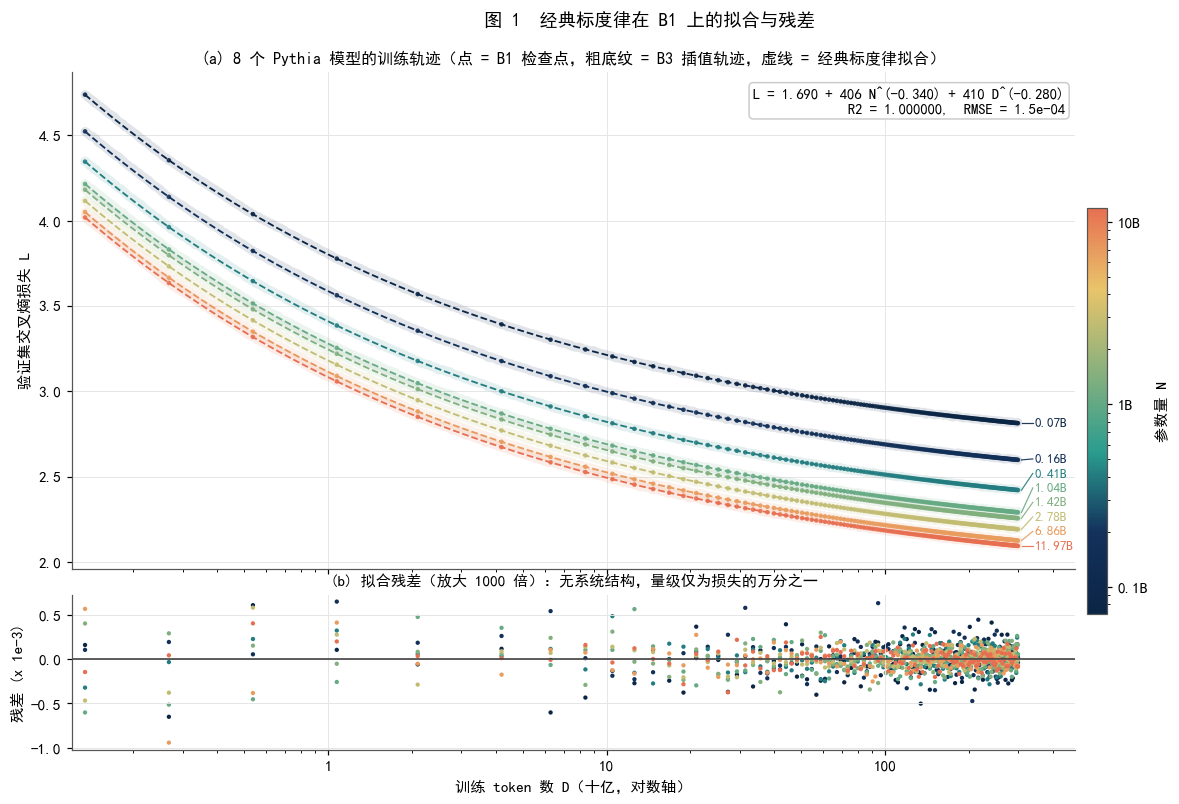

In [3]:
# ============ 1.2 经典标度律拟合（B1 主拟合）+ 留一模型外推检验 ============
def L_classic(N, D, th):
    return th['E'] + th['A'] * np.asarray(N, float) ** (-th['alpha']) + th['B'] * np.asarray(D, float) ** (-th['beta'])

def fit_classic(N, D, L, delta=1e-3):
    N = np.asarray(N, float); D = np.asarray(D, float); L = np.asarray(L, float)
    def pred(x): return np.exp(x[2]) + np.exp(x[0]) * N ** (-x[3]) + np.exp(x[1]) * D ** (-x[4])
    def obj(x):
        r = np.log(pred(x)) - np.log(L)
        return np.where(np.abs(r) < delta, 0.5 * r ** 2, delta * (np.abs(r) - 0.5 * delta)).sum()
    best = None
    for a0, b0, e0, al0, be0 in itertools.product([2, 8, 14], [2, 8, 14], [-0.3, 0.3, 0.9], [0.15, 0.35, 0.6], [0.15, 0.35, 0.6]):
        r = minimize(obj, [a0, b0, e0, al0, be0], method='L-BFGS-B', bounds=[(-5, 30), (-5, 30), (-3, 2), (0.01, 1.5), (0.01, 1.5)])
        if best is None or r.fun < best.fun: best = r
    x = best.x
    return {'E': float(np.exp(x[2])), 'A': float(np.exp(x[0])), 'alpha': float(x[3]), 'B': float(np.exp(x[1])), 'beta': float(x[4]), 'huber': float(best.fun)}

def r2(y, yh): y = np.asarray(y); yh = np.asarray(yh); return 1 - ((y - yh) ** 2).sum() / ((y - y.mean()) ** 2).sum()
def rmse(y, yh): return float(np.sqrt(((np.asarray(y) - np.asarray(yh)) ** 2).mean()))

t0 = time.time(); TH = fit_classic(B1.N, B1.D, B1.val_loss); print('多起点拟合耗时 %.1fs' % (time.time() - t0))
B1['pred'] = L_classic(B1.N, B1.D, TH); B1['res'] = B1.val_loss - B1.pred
print('经典标度律 (B1 主拟合):  E = %.4f  A = %.1f  alpha = %.4f  B = %.1f  beta = %.4f' % (TH['E'], TH['A'], TH['alpha'], TH['B'], TH['beta']))
print('  R2 = %.6f   RMSE = %.5f   最大绝对残差 = %.5f   （残差量级 1e-4：该日志与标度律形式几乎精确一致）' % (r2(B1.val_loss, B1.pred), rmse(B1.val_loss, B1.pred), B1.res.abs().max()))
a_exp, b_exp = TH['beta'] / (TH['alpha'] + TH['beta']), TH['alpha'] / (TH['alpha'] + TH['beta'])
G_const = (TH['alpha'] * TH['A'] / (TH['beta'] * TH['B'])) ** (1 / (TH['alpha'] + TH['beta']))
def N_opt(C): return G_const * (np.asarray(C, float) / 6) ** a_exp
def D_opt(C): return (np.asarray(C, float) / 6) / N_opt(C)
print('计算最优前沿: N* = %.3g (C/6)^%.4f,  D* = (C/6)/N*,  D*/N* 随 C^%.4f 增长' % (G_const, a_exp, (TH['alpha'] - TH['beta']) / (TH['alpha'] + TH['beta'])))
for C in (1e19, 1e22, 1e24):
    print('  C = %.0e FLOPs:  N* = %.3g B 参数,  D* = %.3g B tokens,  D*/N* = %.1f,  L* = %.4f' % (C, N_opt(C) / 1e9, D_opt(C) / 1e9, D_opt(C) / N_opt(C), L_classic(N_opt(C), D_opt(C), TH)))

# 留一模型（leave-one-N-out）外推检验：用其余 7 个模型拟合，预测被留出模型的整条轨迹
jk = []
for n_ in sorted(B1.N.unique()):
    m = B1.N != n_; th = fit_classic(B1.N[m], B1.D[m], B1.val_loss[m]); ph = L_classic(B1.N[~m], B1.D[~m], th)
    jk.append({'留出模型 N (B)': n_ / 1e9, 'alpha': th['alpha'], 'beta': th['beta'], 'E': th['E'], '留出轨迹 RMSE': rmse(B1.val_loss[~m], ph), '终点损失误差': float(ph[-1] - B1.val_loss[~m].iloc[-1])})
JK = pd.DataFrame(jk); print('\n留一模型外推检验（含最小与最大模型的外推）:'); display(JK)
JK.to_csv(TAB / 'classic_law_jackknife.csv', index=False, encoding='utf-8-sig')
pd.Series(TH).to_csv(TAB / 'classic_law_params.csv', encoding='utf-8-sig')

# ---- 图 1：B1 训练轨迹扇面 + 拟合曲线 + 残差带（B3 插值轨迹作底纹） ----
sizes = sorted(B1.N.unique()); norm = mpl.colors.LogNorm(vmin=min(sizes), vmax=max(sizes))
fig = plt.figure(figsize=(14, 8)); gs = gridspec.GridSpec(2, 1, height_ratios=[3.2, 1], hspace=0.08)
ax = fig.add_subplot(gs[0])
Dgrid = np.logspace(np.log10(B1.D.min()), np.log10(B1.D.max()), 300)
for n_ in sizes:
    c = CMAP_SIZE(norm(n_)); g = B1[B1.N == n_]; g3 = B3[np.isclose(B3.N, n_)]
    ax.plot(g3.D / 1e9, g3.val_loss, color=c, lw=6, alpha=0.12, solid_capstyle='round')          # B3 插值轨迹作底纹
    ax.scatter(g.D / 1e9, g.val_loss, s=9, color=c, alpha=0.9, edgecolor='none', zorder=3)
    ax.plot(Dgrid / 1e9, L_classic(n_, Dgrid, TH), color=c, lw=1.2, ls='--', zorder=2)
# 轨迹终点标签：大模型终点损失很接近，做最小间距"排斥"并用细引线连接，避免文字重叠
ends = [(n_, float(B1[B1.N == n_].val_loss.iloc[-1])) for n_ in sizes]; ys = np.array([e[1] for e in ends]); ylab = ys.copy(); order_ = np.argsort(ys); mingap = 0.085
for k in range(1, len(order_)):
    i0, i1 = order_[k - 1], order_[k]
    if ylab[i1] - ylab[i0] < mingap: ylab[i1] = ylab[i0] + mingap
xend = B1.D.max() / 1e9
for (n_, y0), yl in zip(ends, ylab):
    c = CMAP_SIZE(norm(n_)); ax.plot([xend * 1.03, xend * 1.13], [y0, yl], color=c, lw=0.8, alpha=0.9); ax.text(xend * 1.15, yl, '%.2fB' % (n_ / 1e9), color=c, fontsize=8.5, va='center')
ax.set_xscale('log'); ax.xaxis.set_major_formatter(plain); ax.set_xlim(B1.D.min() / 1e9 * 0.9, B1.D.max() / 1e9 * 1.6)
ax.set_ylabel('验证集交叉熵损失 L'); ax.set_title('(a) 8 个 Pythia 模型的训练轨迹（点 = B1 检查点，粗底纹 = B3 插值轨迹，虚线 = 经典标度律拟合）', fontsize=10.5)
ax.text(0.99, 0.97, 'L = %.3f + %.0f N^(-%.3f) + %.0f D^(-%.3f)\nR2 = %.6f,  RMSE = %.1e' % (TH['E'], TH['A'], TH['alpha'], TH['B'], TH['beta'], r2(B1.val_loss, B1.pred), rmse(B1.val_loss, B1.pred)), transform=ax.transAxes, ha='right', va='top', fontsize=9.5, bbox=dict(boxstyle='round', fc='white', ec='#CCCCCC'))
ax.tick_params(labelbottom=False)
ax2 = fig.add_subplot(gs[1], sharex=ax)
ax2.scatter(B1.D / 1e9, B1.res * 1e3, s=8, c=[CMAP_SIZE(norm(v)) for v in B1.N], edgecolor='none'); ax2.axhline(0, color='#333333', lw=1)
ax2.set_xscale('log'); ax2.xaxis.set_major_formatter(plain); ax2.set_xlabel('训练 token 数 D（十亿，对数轴）'); ax2.set_ylabel('残差 (x 1e-3)')
ax2.set_title('(b) 拟合残差（放大 1000 倍）：无系统结构，量级仅为损失的万分之一', fontsize=10)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=CMAP_SIZE); cb = fig.colorbar(sm, ax=[ax, ax2], shrink=0.6, pad=0.01, format=mpl.ticker.FuncFormatter(lambda v, _: '%gB' % (v / 1e9))); cb.set_label('参数量 N')
fig.suptitle('图 1  经典标度律在 B1 上的拟合与残差', fontsize=12, y=0.95)
savefig('fig01_b1_trajectories_fit.png'); plt.show()

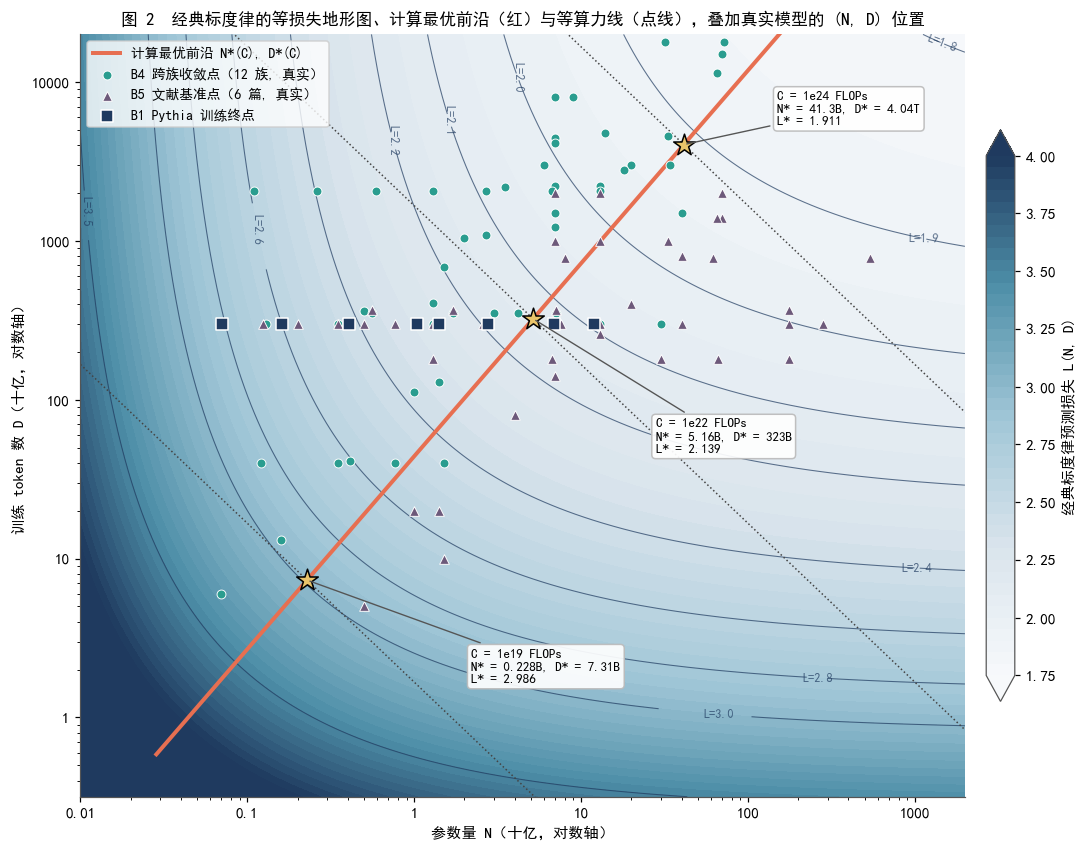

In [4]:
# ---- 图 2：(N, D) 平面上的等损失地形图 + 计算最优前沿 + 等算力线 + 真实模型（B4/B5）散点 ----
Ng = np.logspace(7, 12.3, 260); Dg = np.logspace(8.5, 13.3, 260); NN, DD = np.meshgrid(Ng, Dg)
LL = L_classic(NN, DD, TH)
fig, ax = plt.subplots(figsize=(12.5, 9))
cf = ax.contourf(NN / 1e9, DD / 1e9, LL, levels=np.linspace(1.75, 4.0, 46), cmap=CMAP_TERRAIN, extend='both')
cs = ax.contour(NN / 1e9, DD / 1e9, LL, levels=[1.8, 1.9, 2.0, 2.1, 2.2, 2.4, 2.6, 2.8, 3.0, 3.5], colors='#1F3A5F', linewidths=0.7, alpha=0.7)
ax.clabel(cs, fmt=lambda v: 'L=%.1f' % v, fontsize=8, inline=True)
Cs = np.logspace(17, 27, 200); ax.plot(N_opt(Cs) / 1e9, D_opt(Cs) / 1e9, color=C_CORAL, lw=2.6, label='计算最优前沿 N*(C), D*(C)')
def fmtB(x):                                     # 十亿 -> 'xxB' / 'x.xxT'
    return '%.2fT' % (x / 1000) if x >= 1000 else '%.3gB' % x
for C, lab_, xy_txt in ((1e19, '1e19', (2.2, 1.6)), (1e22, '1e22', (28, 45)), (1e24, '1e24', (150, 5200))):   # 注释框放在无散点的空白区，用引线指向星标
    Nl = np.logspace(7, 12.3, 100); ax.plot(Nl / 1e9, (C / 6 / Nl) / 1e9, color='#444444', lw=1, ls=':')
    ax.scatter([N_opt(C) / 1e9], [D_opt(C) / 1e9], marker='*', s=220, color=C_GOLD, edgecolor='black', zorder=6)
    ax.annotate('C = %s FLOPs\nN* = %s, D* = %s\nL* = %.3f' % (lab_, fmtB(N_opt(C) / 1e9), fmtB(D_opt(C) / 1e9), L_classic(N_opt(C), D_opt(C), TH)), (N_opt(C) / 1e9, D_opt(C) / 1e9), xytext=xy_txt, textcoords='data', fontsize=8.5, ha='left', va='bottom', bbox=dict(boxstyle='round', fc='white', ec='#BBBBBB', alpha=0.92), arrowprops=dict(arrowstyle='-', color='#555555', lw=0.9), zorder=7)
ax.scatter(B4.N_params_B, B4.D_tokens_B, s=34, color=C_TEAL, edgecolor='white', linewidths=0.6, zorder=5, label='B4 跨族收敛点（12 族, 真实）')
ax.scatter(B5.N_params_B, B5.D_tokens_B, s=40, marker='^', color=C_PLUM, edgecolor='white', linewidths=0.6, zorder=5, label='B5 文献基准点（6 篇, 真实）')
ax.scatter(B1.groupby('N').D.max().index / 1e9, B1.groupby('N').D.max().values / 1e9, s=60, marker='s', color=C_NAVY, edgecolor='white', zorder=5, label='B1 Pythia 训练终点')
ax.set_xscale('log'); ax.set_yscale('log'); ax.xaxis.set_major_formatter(plain); ax.yaxis.set_major_formatter(plain)
ax.set_xlim(Ng.min() / 1e9, Ng.max() / 1e9); ax.set_ylim(Dg.min() / 1e9, Dg.max() / 1e9)
ax.set_xlabel('参数量 N（十亿，对数轴）'); ax.set_ylabel('训练 token 数 D（十亿，对数轴）')
cb = plt.colorbar(cf, ax=ax, shrink=0.75, pad=0.02); cb.set_label('经典标度律预测损失 L(N, D)'); ax.grid(False)
ax.legend(loc='upper left', frameon=True, fontsize=9)
ax.set_title('图 2  经典标度律的等损失地形图、计算最优前沿（红）与等算力线（点线），叠加真实模型的 (N, D) 位置', fontsize=11)
savefig('fig02_isoloss_terrain_frontier.png'); plt.show()

## 2. 跨来源验证：可检验假设 H1（规模骨架迁移）

附件 B 内不同来源使用不同训练细节与验证设置，损失的绝对水平不可直接拼接。这里不再假定所有模型族严格共享同一组 $\alpha,\beta$，而提出更弱、也更符合数据的结构假设：

> **H1（规模骨架迁移）**：经典标度律诱导的可约损失坐标
> $$R(N,D)=AN^{-\alpha}+BD^{-\beta}$$
> 在不同来源中保持稳定的单调结构；来源 $f$ 的绝对损失差异由偏移 $E_f$ 与可约部分乘子 $s_f$ 吸收，具体指数允许存在跨族漂移：
> $$L_f(N,D)=E_f+s_fR(N,D).$$

检验分四层：B2 固定 B1 指数作为**迁移基准**并与自由指数模型比较；B3 检验插值轨迹；B4/B5 比较“仅偏移”与“偏移 + 乘子”两个嵌套模型并进行组内留一验证；同时计算 $R(N,D)$ 对真实损失的 Spearman。第 6 节再用 B4（按模型族）和 B5（按文献来源）重抽样重新识别 $\alpha,\beta$，把指数漂移显式传播到外推不确定性，而不把 B1 指数宣称为跨族普适常数。

**现有结果的含义**。B2 中 B1 指数迁移模型 $R^2=0.9995$、RMSE $=0.0108$，自由拟合指数与 B1 仅差约 0.001；B3 的 4,000 个插值点 $R^2=0.99996$、RMSE $=0.0038$。B4/B5 的“偏移 + 乘子”模型分别达到 $R^2=0.992/0.940$，Spearman 为 $0.983/0.959$，说明 $R(N,D)$ 作为跨来源**规模坐标**具有较强迁移能力。另一方面，第 6 节真实跨族重估显示指数存在来源不确定性，因此后续中心模型使用 B1 标度律，而跨族指数分布只用于敏感性与外推区间。


B2 Cerebras 族外验证:
  B1指数迁移 (alpha=0.340, beta=0.280) + 自估 E,A,B = (1.690, 407.7, 2829.5):  R2 = 0.9995  RMSE = 0.0108
  完全自由拟合:  E=1.680 A=399.6 alpha=0.339 B=2763.0 beta=0.279:  R2 = 0.9995  RMSE = 0.0108
  -> 自由拟合的指数与 B1 仅差 0.001 / 0.001，B1指数迁移造成的精度损失很小（Cerebras 的 B 常数约为 Pythia 的 6.9 倍：同一 D 带来的可约损失更大）

B3 插值轨迹验证: 4,000 点 R2 = 0.99996, RMSE = 0.0038, 最大绝对误差 = 0.0147

B4 跨族收敛点（12 组）:
  仅偏移 E_f:        R2 = 0.887  RMSE = 0.1562  AIC = -187.6
  偏移 + 乘子 s_f:   R2 = 0.992  RMSE = 0.0421  AIC = -319.2
  族内留一交叉验证 (n>=4 的组, 49 点): RMSE = 0.0678
  R(N,D) 与真实损失的 Spearman = 0.983

B5 文献基准点（6 组）:
  仅偏移 E_f:        R2 = 0.888  RMSE = 0.1276  AIC = -169.2
  偏移 + 乘子 s_f:   R2 = 0.940  RMSE = 0.0934  AIC = -184.7
  族内留一交叉验证 (n>=4 的组, 41 点): RMSE = 0.1262
  R(N,D) 与真实损失的 Spearman = 0.959

仅用真实收敛点自由拟合指数（不可靠，仅作对照）: B4 -> alpha=0.171 beta=0.428 E=1.309;  B5 -> alpha=0.228 beta=0.113 E=0.050


,来源,n,E_f(仅偏移),E_f(偏移+乘子),s_f,N范围(B),附件
0,BLOOM,4,1.9838,1.5796,1.7645,0.56-7.1,B4
1,Cerebras-GPT,7,1.8758,1.5772,1.5694,0.11-13,B4
2,Falcon,2,1.8480,1.8480,NaN,7-40,B4
3,GPT2,4,1.9011,2.1569,0.7231,0.12-1.5,B4
4,Gemma,3,1.8544,1.6245,1.6710,2-9,B4
5,LLaMA,6,1.7622,1.3947,2.3890,3.5-70,B4
6,Mistral,1,1.8171,1.8171,NaN,7-7,B4
7,OPT,7,1.9708,1.6021,1.6462,0.13-30,B4
8,Phi,6,1.8736,1.6498,1.5921,1.3-18,B4
9,Pythia,8,2.1333,1.5204,1.7581,0.07-12,B4


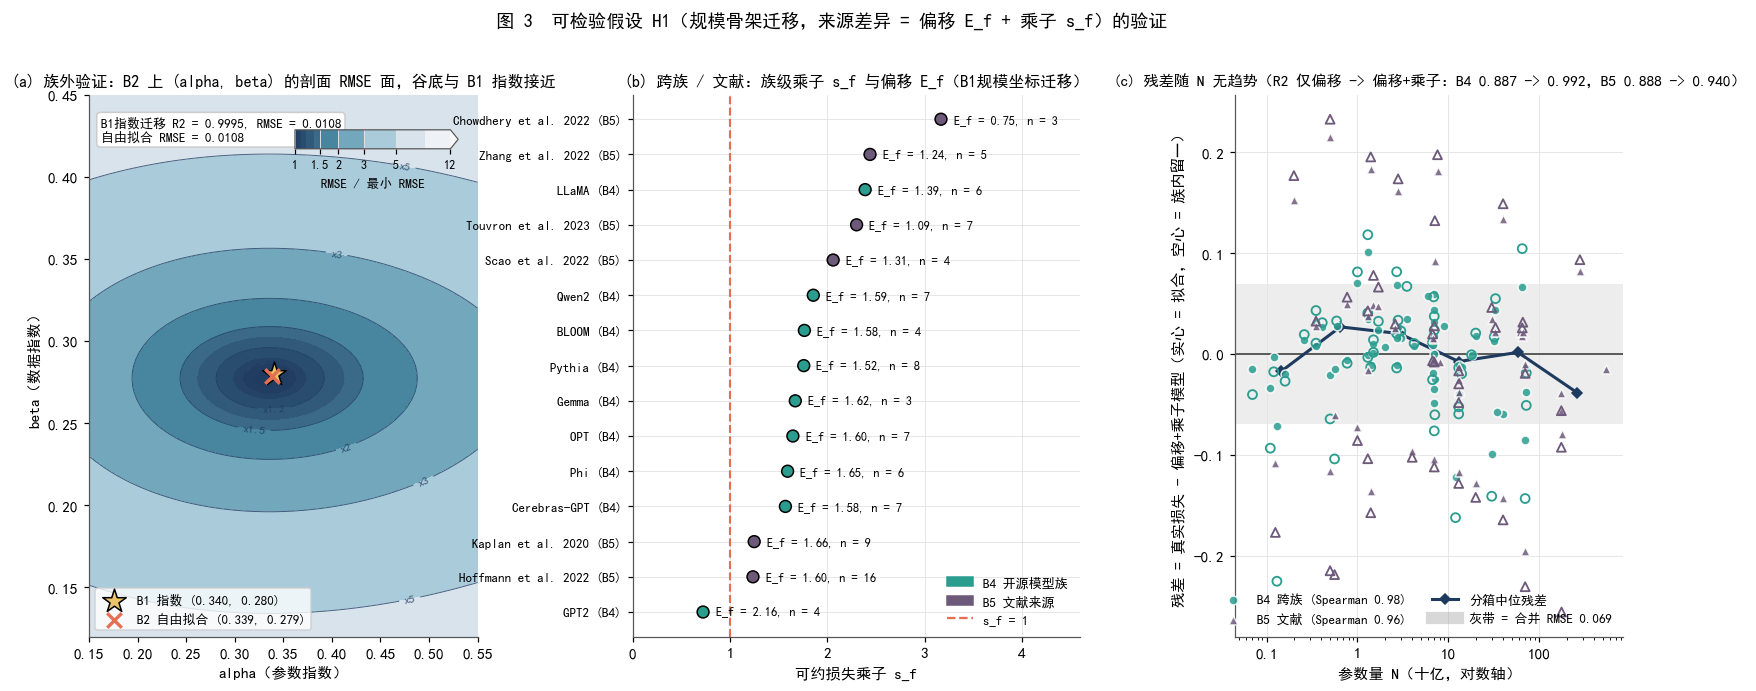

In [5]:
# ============ 2. H1 检验 ============
def R_fun(N, D, th=None):
    th = TH if th is None else th
    return th['A'] * np.asarray(N, float) ** (-th['alpha']) + th['B'] * np.asarray(D, float) ** (-th['beta'])

# (1) B2 族外验证
X2 = np.column_stack([np.ones(len(B2)), B2.N ** (-TH['alpha']), B2.D ** (-TH['beta'])])
coef2, _, _, _ = np.linalg.lstsq(X2, B2.val_loss.values, rcond=None); B2['pred_shared'] = X2 @ coef2
TH2 = fit_classic(B2.N, B2.D, B2.val_loss); B2['pred_free'] = L_classic(B2.N, B2.D, TH2)
print('B2 Cerebras 族外验证:')
print('  B1指数迁移 (alpha=%.3f, beta=%.3f) + 自估 E,A,B = (%.3f, %.1f, %.1f):  R2 = %.4f  RMSE = %.4f' % (TH['alpha'], TH['beta'], coef2[0], coef2[1], coef2[2], r2(B2.val_loss, B2.pred_shared), rmse(B2.val_loss, B2.pred_shared)))
print('  完全自由拟合:  E=%.3f A=%.1f alpha=%.3f B=%.1f beta=%.3f:  R2 = %.4f  RMSE = %.4f' % (TH2['E'], TH2['A'], TH2['alpha'], TH2['B'], TH2['beta'], r2(B2.val_loss, B2.pred_free), rmse(B2.val_loss, B2.pred_free)))
print('  -> 自由拟合的指数与 B1 仅差 %.3f / %.3f，B1指数迁移造成的精度损失很小（Cerebras 的 B 常数约为 Pythia 的 %.1f 倍：同一 D 带来的可约损失更大）' % (abs(TH2['alpha'] - TH['alpha']), abs(TH2['beta'] - TH['beta']), coef2[2] / TH['B']))

# (2) B3 插值轨迹验证
B3['pred'] = L_classic(B3.N, B3.D, TH)
print('\nB3 插值轨迹验证: 4,000 点 R2 = %.5f, RMSE = %.4f, 最大绝对误差 = %.4f' % (r2(B3.val_loss, B3.pred), rmse(B3.val_loss, B3.pred), (B3.val_loss - B3.pred).abs().max()))

# (3)(4) B4 / B5 族级模型
def family_models(df, key):
    R = R_fun(df.N, df.D); out = df.copy(); out['R'] = R; rows = []
    out['pred_offset'] = np.nan; out['pred_scale'] = np.nan; out['loo_scale'] = np.nan
    for f, g in out.groupby(key):
        idx = g.index; Ef = (g.val_loss - g.R).mean(); out.loc[idx, 'pred_offset'] = Ef + g.R
        if len(g) >= 3:
            X = np.column_stack([np.ones(len(g)), g.R]); c, _, _, _ = np.linalg.lstsq(X, g.val_loss.values, rcond=None); out.loc[idx, 'pred_scale'] = X @ c; E_s, s_f = c
            if len(g) >= 4:
                for i in idx:
                    gg = g.drop(i); Xg = np.column_stack([np.ones(len(gg)), gg.R]); cc, _, _, _ = np.linalg.lstsq(Xg, gg.val_loss.values, rcond=None)
                    out.loc[i, 'loo_scale'] = cc[0] + cc[1] * out.loc[i, 'R']
        else:
            out.loc[idx, 'pred_scale'] = Ef + g.R; E_s, s_f = Ef, np.nan
        rows.append({'来源': f, 'n': len(g), 'E_f(仅偏移)': Ef, 'E_f(偏移+乘子)': E_s, 's_f': s_f, 'N范围(B)': '%.2g-%.3g' % (g.N_params_B.min(), g.N_params_B.max())})
    return out, pd.DataFrame(rows)
B4m, FAM4 = family_models(B4, 'family'); B5m, FAM5 = family_models(B5, 'source')
def aic(y, yh, k): n = len(y); return n * np.log(((np.asarray(y) - np.asarray(yh)) ** 2).mean()) + 2 * k
for name, dfm, fam, key in (('B4 跨族收敛点', B4m, FAM4, 'family'), ('B5 文献基准点', B5m, FAM5, 'source')):
    k1 = fam.shape[0]; k2 = k1 + fam['s_f'].notna().sum()
    print('\n%s（%d 组）:' % (name, k1))
    print('  仅偏移 E_f:        R2 = %.3f  RMSE = %.4f  AIC = %.1f' % (r2(dfm.val_loss, dfm.pred_offset), rmse(dfm.val_loss, dfm.pred_offset), aic(dfm.val_loss, dfm.pred_offset, k1)))
    print('  偏移 + 乘子 s_f:   R2 = %.3f  RMSE = %.4f  AIC = %.1f' % (r2(dfm.val_loss, dfm.pred_scale), rmse(dfm.val_loss, dfm.pred_scale), aic(dfm.val_loss, dfm.pred_scale, k2)))
    m = dfm.loo_scale.notna(); print('  族内留一交叉验证 (n>=4 的组, %d 点): RMSE = %.4f' % (m.sum(), rmse(dfm.val_loss[m], dfm.loo_scale[m])))
    print('  R(N,D) 与真实损失的 Spearman = %.3f' % stats.spearmanr(dfm.R, dfm.val_loss)[0])
TH4 = fit_classic(B4.N, B4.D, B4.val_loss); TH5 = fit_classic(B5.N, B5.D, B5.val_loss)
print('\n仅用真实收敛点自由拟合指数（不可靠，仅作对照）: B4 -> alpha=%.3f beta=%.3f E=%.3f;  B5 -> alpha=%.3f beta=%.3f E=%.3f' % (TH4['alpha'], TH4['beta'], TH4['E'], TH5['alpha'], TH5['beta'], TH5['E']))
FAM = pd.concat([FAM4.assign(附件='B4'), FAM5.assign(附件='B5')], ignore_index=True); display(FAM)
FAM.to_csv(TAB / 'family_offsets_scales.csv', index=False, encoding='utf-8-sig')

# ---- 图 3：H1 检验三联图 ----
fig = plt.figure(figsize=(18, 6.4)); gs = gridspec.GridSpec(1, 3, width_ratios=[1, 1.15, 1], wspace=0.38)
ax = fig.add_subplot(gs[0])
# (a) 指数剖面：在 (alpha, beta) 网格上，对 B2 用线性最小二乘解 (E, A, B)，得到 RMSE 面——最小点是否落在 B1 的指数上，是 H1 的直接检验
ag = np.linspace(0.15, 0.55, 81); bg = np.linspace(0.12, 0.45, 81); AG, BG = np.meshgrid(ag, bg); RM = np.empty_like(AG)
N2_, D2_, y2_ = B2.N.values, B2.D.values, B2.val_loss.values
for i_ in range(AG.shape[0]):
    for j_ in range(AG.shape[1]):
        X_ = np.column_stack([np.ones(len(y2_)), N2_ ** (-AG[i_, j_]), D2_ ** (-BG[i_, j_])]); c_, _, _, _ = np.linalg.lstsq(X_, y2_, rcond=None); RM[i_, j_] = np.sqrt(((X_ @ c_ - y2_) ** 2).mean())
RMr = RM / RM.min()
cf = ax.contourf(AG, BG, RMr, levels=[1, 1.02, 1.05, 1.1, 1.2, 1.35, 1.5, 2, 3, 5, 8, 12], cmap=CMAP_TERRAIN.reversed(), norm=mpl.colors.LogNorm(vmin=1, vmax=12), extend='max')
cs = ax.contour(AG, BG, RMr, levels=[1.05, 1.2, 1.5, 2, 3, 5], colors='#1F3A5F', linewidths=0.6, alpha=0.8); ax.clabel(cs, fmt=lambda v: 'x%g' % v, fontsize=7.5)
ax.scatter([TH['alpha']], [TH['beta']], marker='*', s=260, color=C_GOLD, edgecolor='black', zorder=6, label='B1 指数 (%.3f, %.3f)' % (TH['alpha'], TH['beta']))
ax.scatter([TH2['alpha']], [TH2['beta']], marker='x', s=90, color=C_CORAL, linewidths=2.2, zorder=6, label='B2 自由拟合 (%.3f, %.3f)' % (TH2['alpha'], TH2['beta']))
ax.set_xlabel('alpha（参数指数）'); ax.set_ylabel('beta（数据指数）'); ax.grid(False); ax.legend(loc='lower left', frameon=True, fontsize=8.5)
cax = ax.inset_axes([0.53, 0.9, 0.42, 0.035]); cb = plt.colorbar(cf, cax=cax, orientation='horizontal', ticks=[1, 1.5, 2, 3, 5, 12], format=plain); cb.set_label('RMSE / 最小 RMSE', fontsize=8.5); cax.tick_params(labelsize=8)
ax.text(0.03, 0.96, 'B1指数迁移 R2 = %.4f, RMSE = %.4f\n自由拟合 RMSE = %.4f' % (r2(B2.val_loss, B2.pred_shared), rmse(B2.val_loss, B2.pred_shared), rmse(B2.val_loss, B2.pred_free)), transform=ax.transAxes, va='top', fontsize=8.5, bbox=dict(boxstyle='round', fc='white', ec='#CCCCCC'))
ax.set_title('(a) 族外验证：B2 上 (alpha, beta) 的剖面 RMSE 面，谷底与 B1 指数接近', fontsize=10.5)
ax = fig.add_subplot(gs[1])
famp = FAM.dropna(subset=['s_f']).sort_values('s_f'); y = np.arange(len(famp))
ax.scatter(famp['s_f'], y, s=60, color=[C_TEAL if a == 'B4' else C_PLUM for a in famp['附件']], edgecolor='black', zorder=3)
ax.axvline(1, color=C_CORAL, ls='--', lw=1.4, label='s_f = 1（与 Pythia 相同）')
for yi, (_, r) in zip(y, famp.iterrows()):
    ax.text(r['s_f'] + 0.13, yi, 'E_f = %.2f, n = %d' % (r['E_f(偏移+乘子)'], r['n']), va='center', fontsize=8)
ax.set_yticks(y); ax.set_yticklabels([('%s (%s)' % (r['来源'], r['附件'])) for _, r in famp.iterrows()], fontsize=8.5)
ax.set_xlabel('可约损失乘子 s_f'); ax.set_xlim(0, famp['s_f'].max() * 1.45)
ax.legend(handles=[Patch(color=C_TEAL, label='B4 开源模型族'), Patch(color=C_PLUM, label='B5 文献来源'), Line2D([0], [0], color=C_CORAL, ls='--', label='s_f = 1')], frameon=False, fontsize=8.5, loc='lower right')
ax.set_title('(b) 跨族 / 文献：族级乘子 s_f 与偏移 E_f（B1规模坐标迁移）', fontsize=10.5)
ax = fig.add_subplot(gs[2])
# (c) 残差随 N 的分布：若指数随规模漂移，残差会呈现随 N 的系统趋势；空心点为族内留一预测的残差
allres = []
for dfm, c, lab_, mk in ((B4m, C_TEAL, 'B4 跨族 (Spearman %.2f)' % stats.spearmanr(B4m.R, B4m.val_loss)[0], 'o'), (B5m, C_PLUM, 'B5 文献 (Spearman %.2f)' % stats.spearmanr(B5m.R, B5m.val_loss)[0], '^')):
    ax.scatter(dfm.N / 1e9, dfm.val_loss - dfm.pred_scale, s=34, marker=mk, color=c, alpha=0.85, edgecolor='white', label=lab_, zorder=3)
    m = dfm.loo_scale.notna(); ax.scatter(dfm.N[m] / 1e9, dfm.val_loss[m] - dfm.loo_scale[m], s=34, marker=mk, facecolors='none', edgecolors=c, linewidths=1.2, zorder=3)
    allres.append(pd.DataFrame({'N': dfm.N.values, 'r': (dfm.val_loss - dfm.pred_scale).values}))
allres = pd.concat(allres); rm_all = np.sqrt((allres.r ** 2).mean())
ax.axhspan(-rm_all, rm_all, color=C_GREY, alpha=0.18, lw=0); ax.axhline(0, color='#333333', lw=1)
bins_ = np.logspace(np.log10(allres.N.min()) - 0.01, np.log10(allres.N.max()) + 0.01, 7); mid_ = np.sqrt(bins_[1:] * bins_[:-1])
med_ = [allres.r[(allres.N >= lo) & (allres.N < hi)].median() for lo, hi in zip(bins_[:-1], bins_[1:])]
ax.plot(mid_ / 1e9, med_, color=C_NAVY, lw=2, marker='D', ms=5, label='分箱中位残差')
ax.set_xscale('log'); ax.xaxis.set_major_formatter(plain); ax.set_xlabel('参数量 N（十亿，对数轴）'); ax.set_ylabel('残差 = 真实损失 - 偏移+乘子模型（实心 = 拟合，空心 = 族内留一）')
ax.plot([], [], color=C_GREY, lw=8, alpha=0.4, label='灰带 = 合并 RMSE %.3f' % rm_all)
ax.legend(frameon=False, fontsize=8.5, loc='lower right', ncol=2); ax.set_title('(c) 残差随 N 无趋势（R2 仅偏移 -> 偏移+乘子：B4 %.3f -> %.3f，B5 %.3f -> %.3f）' % (r2(B4m.val_loss, B4m.pred_offset), r2(B4m.val_loss, B4m.pred_scale), r2(B5m.val_loss, B5m.pred_offset), r2(B5m.val_loss, B5m.pred_scale)), fontsize=10)
fig.suptitle('图 3  可检验假设 H1（规模骨架迁移，来源差异 = 偏移 E_f + 乘子 s_f）的验证', fontsize=12, y=1.0)
savefig('fig03_H1_cross_family.png'); plt.show()


## 3. 质量项：可检验假设 H3 与 B6/B7 上的形式识别

B6–B8 为半合成 N-D-Q 数据，只用于识别质量进入标度律的函数形式与强度，不把它们表述为真实训练实验。为避免训练—验证信息交叉，本节把数据角色固定为：

* **B6（360 点）**：六种质量形式的 AIC 比较、自由曲率参数检验、$\kappa$ 估计；
* **B7 新增 $Q=\{0.5,0.7\}$ 的 90 点**：完全隔离，仅用于最终外层预测验证；
* **B8**：仅用于方向一致性和异常边界敏感性。

候选形式仍保持同一经典骨架：

| 编号 | 形式 | 含义 |
|---|---|---|
| F1 | $E+AN^{-\alpha}+B(DQ^\gamma)^{-\beta}$ | 质量只折损有效 token |
| F1b | $E+AN^{-\alpha}+B(De^{-k(1-Q)})^{-\beta}$ | 指数型 token 折损 |
| F2 | $E+R(N,D)[1+\kappa(1-Q)^\gamma]$ | **质量乘在整个可约损失上** |
| F3 | $E+R(N,D)+\kappa(1-Q)^\gamma$ | 与规模无关的附加损失 |
| F5 | $E[1+\kappa(1-Q)^\gamma]+R(N,D)$ | 抬高不可约损失 |
| F6 | $E+A(NQ^{\gamma_1})^{-\alpha}+B(DQ^{\gamma_2})^{-\beta}$ | 同时折损有效参数与 token |

> **H3（质量乘子）**：若 B6 支持 F2 且自由 $\gamma$ 的区间包含 1，则采用最简线性形式
> $$\boxed{\psi_Q(Q)=1+\kappa(1-Q)},\qquad L=E+R(N,D)\psi_Q(Q).$$

形式识别、参数估计和 Bootstrap 均只使用 B6；代码设置一致性检查，若 B6 不支持 F2 则停止运行而不是继续套用该形式。最终 $\kappa$ 用 $(N,D)$ 单元整体重抽的 cluster bootstrap 评估不确定性。

**外层验证结果**。固定线性质量乘子后，仅用 B6 估计得到
$$\boxed{\kappa=0.4597},\qquad 95\%\ \text{cluster-bootstrap 区间}=[0.4378,0.4873].$$
对 B7 中从未参与形式选择或参数估计的 $Q=0.5,0.7$ 共 90 点预测：
$$\boxed{\mathrm{RMSE}=0.04671,\qquad R^2=0.9789},$$
误差低于 B7 中 $Q=1$ 相对经典定律约 0.055 的噪声标准差。B6 的 45 个 $(N,D)$ 单元中损失随 $Q$ 增大而下降的比例为 100%；B8 则出现完全相反的方向并伴随 $Q\le0.4$ 的截断值，因此只保留为敏感性证据，不进入参数估计。

方向一致性检验:
  B6: 45 个 (N,D) 单元，损失随 Q 下降的单元占 100%，Q 斜率中位数 -0.341
  B7: 45 个 (N,D) 单元，损失随 Q 下降的单元占 100%，Q 斜率中位数 -0.339
  B8(calibrated): 90 个 (N,D) 单元，损失随 Q 下降的单元占 0%，Q 斜率中位数 2.028
  B8(全部): 150 个 (N,D) 单元，损失随 Q 下降的单元占 0%，Q 斜率中位数 1.972
  B8 中 val_loss == 0.5 的截断点数: 364 (21.4%)，且全部出现在 Q <= 0.40
  B6 中 Q=1 的点相对 B1 定律的残差: 均值 0.0036, 标准差 0.0551

候选形式比较（仅 B6 训练集，B7 新 Q 未参与）:


,形式,参数,RMSE,AIC,dAIC
0,F2 R (1 + k (1-Q)^g),"[0.4587, 0.9935]",0.0594,-2029.2443,0.0000
1,F3 R + k (1-Q)^g,"[0.3622, 0.9907]",0.0761,-1850.7992,178.4451
2,F5 E (1 + k (1-Q)^g) + R,"[0.2143, 0.9907]",0.0761,-1850.7992,178.4451
3,"F6 N_eff = N Q^g1, D_eff = D Q^g2","[0.5971, 0.5454]",0.0806,-1809.4949,219.7494
4,F1b D_eff = D exp(-k(1-Q)),[2.3547],0.1029,-1635.0545,394.1899
5,F1 D_eff = D Q^g,[1.0524],0.1170,-1542.9770,486.2673



最终质量项: psi_Q=1+kappa(1-Q)
  B6: kappa=0.4597, gamma_free=0.9935, gamma cluster-bootstrap 95%=[0.925, 1.079]
  kappa cluster-bootstrap 95%=[0.4378, 0.4873]
  B7 新 Q 外层验证: RMSE=0.04671, R2=0.9789
  B8 敏感性: 若用于估计，全部 / calibrated kappa = -2.812 / -2.488；与 B6/B7 方向相反，故不进入参数估计。


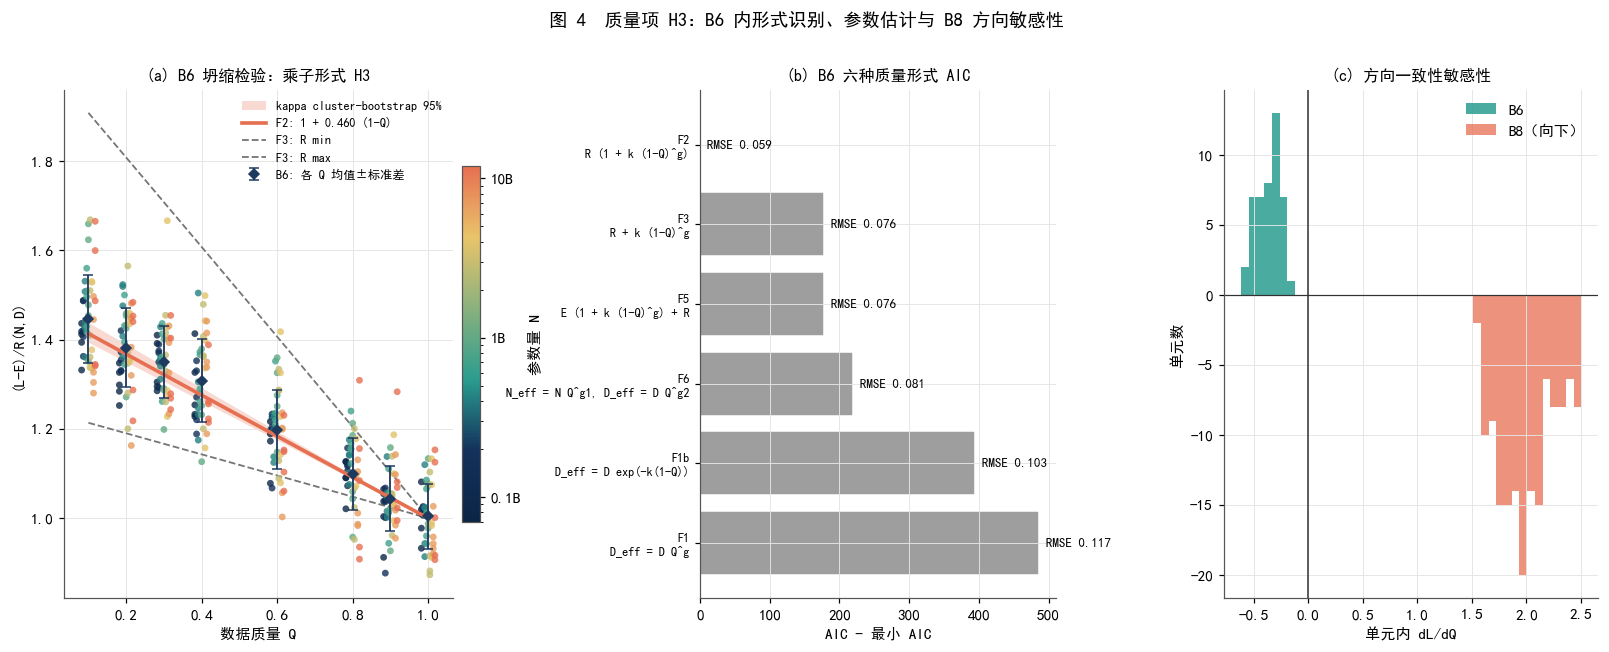

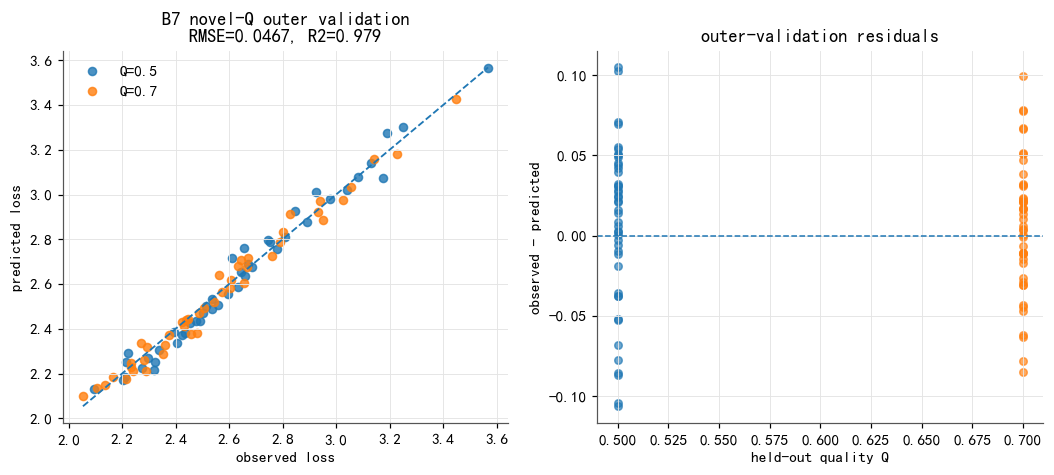

In [6]:
# ============ 3. 质量项：B6 内形式识别 + B7 新 Q 外层验证 ============
QUALITY_SEED = 20260924
Q_TRAIN = B6.copy()
Q_VALID = B7[~B7.Q_score.isin(B6.Q_score.unique())].copy()
assert set(np.round(Q_VALID.Q_score.unique(), 6)) == {0.5, 0.7}
assert len(Q_TRAIN) == 360 and len(Q_VALID) == 90

def slope_sign_table(df, name):
    rows = []
    for (n_, d_), g in df.groupby(['N_params_B', 'D_tokens_B']):
        if g.Q_score.nunique() >= 3:
            sl = np.polyfit(g.Q_score, g.val_loss, 1)[0]
            rows.append({'N': n_, 'D': d_, 'slope': sl})
    t = pd.DataFrame(rows)
    return t, '%s: %d 个 (N,D) 单元，损失随 Q 下降的单元占 %.0f%%，Q 斜率中位数 %.3f' % (
        name, len(t), 100 * (t.slope < 0).mean(), t.slope.median())

SL6, msg6 = slope_sign_table(B6, 'B6')
SL7, msg7 = slope_sign_table(B7, 'B7')
SL8, msg8 = slope_sign_table(B8[B8.data_type == 'calibrated'], 'B8(calibrated)')
SL8x, msg8x = slope_sign_table(B8, 'B8(全部)')
print('方向一致性检验:'); print(' ', msg6); print(' ', msg7); print(' ', msg8); print(' ', msg8x)
print('  B8 中 val_loss == 0.5 的截断点数: %d (%.1f%%)，且全部出现在 Q <= %.2f' % (
    (B8.val_loss <= 0.5001).sum(), 100 * (B8.val_loss <= 0.5001).mean(),
    B8.loc[B8.val_loss <= 0.5001, 'Q_score'].max()))

q1_res = B6.loc[B6.Q_score == 1, 'val_loss'] - L_classic(
    B6.loc[B6.Q_score == 1, 'N'], B6.loc[B6.Q_score == 1, 'D'], TH)
print('  B6 中 Q=1 的点相对 B1 定律的残差: 均值 %.4f, 标准差 %.4f' % (q1_res.mean(), q1_res.std()))

N6, D6, Q6, L6 = Q_TRAIN.N.values, Q_TRAIN.D.values, Q_TRAIN.Q_score.values, Q_TRAIN.val_loss.values
R6 = R_fun(N6, D6)
NA6 = TH['A'] * N6 ** (-TH['alpha'])
DB6 = TH['B'] * D6 ** (-TH['beta'])
FORMS = {
    'F1  D_eff = D Q^g':                  (lambda th, N, D, Q, R, NA, DB: TH['E'] + NA + TH['B'] * (D * np.maximum(Q, 1e-6) ** th[0]) ** (-TH['beta']), [1.0]),
    'F1b D_eff = D exp(-k(1-Q))':         (lambda th, N, D, Q, R, NA, DB: TH['E'] + NA + TH['B'] * (D * np.exp(-th[0] * (1 - Q))) ** (-TH['beta']), [1.0]),
    'F2  R (1 + k (1-Q)^g)':              (lambda th, N, D, Q, R, NA, DB: TH['E'] + R * (1 + th[0] * (1 - Q) ** th[1]), [0.5, 1.0]),
    'F3  R + k (1-Q)^g':                  (lambda th, N, D, Q, R, NA, DB: TH['E'] + R + th[0] * (1 - Q) ** th[1], [0.5, 1.0]),
    'F5  E (1 + k (1-Q)^g) + R':          (lambda th, N, D, Q, R, NA, DB: TH['E'] * (1 + th[0] * (1 - Q) ** th[1]) + R, [0.3, 1.0]),
    'F6  N_eff = N Q^g1, D_eff = D Q^g2': (lambda th, N, D, Q, R, NA, DB: TH['E'] + TH['A'] * (N * np.maximum(Q, 1e-6) ** th[0]) ** (-TH['alpha']) + TH['B'] * (D * np.maximum(Q, 1e-6) ** th[1]) ** (-TH['beta']), [0.5, 0.5])}

rows, FITS = [], {}
for name, (f, x0) in FORMS.items():
    res = least_squares(lambda th: f(th, N6, D6, Q6, R6, NA6, DB6) - L6, x0, method='trf')
    resid = f(res.x, N6, D6, Q6, R6, NA6, DB6) - L6
    rows.append({'形式': name, '参数': np.round(res.x, 4).tolist(),
                 'RMSE': np.sqrt(np.mean(resid ** 2)),
                 'AIC': len(L6) * np.log(np.mean(resid ** 2)) + 2 * len(x0)})
    FITS[name] = res.x
FORM_CMP = pd.DataFrame(rows).sort_values('AIC').reset_index(drop=True)
FORM_CMP['dAIC'] = FORM_CMP['AIC'] - FORM_CMP['AIC'].min()
print('\n候选形式比较（仅 B6 训练集，B7 新 Q 未参与）:'); display(FORM_CMP)
FORM_CMP.to_csv(TAB / 'quality_form_comparison.csv', index=False, encoding='utf-8-sig')
BEST_QUALITY_FORM = str(FORM_CMP.iloc[0]['形式'])
if not BEST_QUALITY_FORM.startswith('F2'):
    raise RuntimeError('B6 的 AIC 最优形式不是 F2，需重新检查 H3，禁止继续使用线性质量乘子。')

def fit_kappa(N, D, Q, L, gamma_free=False):
    R = R_fun(N, D)
    if gamma_free:
        res = least_squares(lambda th: TH['E'] + R * (1 + th[0] * (1 - Q) ** th[1]) - L,
                            [0.5, 1.0], method='trf', bounds=([0, 0.2], [5, 5]))
        return res.x
    X = (R * (1 - Q)).reshape(-1, 1)
    y = L - TH['E'] - R
    return np.array([float(np.linalg.lstsq(X, y, rcond=None)[0][0])])

# 自由 gamma 仅在 B6 上估计，并以 (N,D) 单元 cluster bootstrap 判断 gamma=1 是否可接受。
free_b6 = fit_kappa(N6, D6, Q6, L6, gamma_free=True)
cell_keys = list(Q_TRAIN.groupby(['N', 'D']).groups.keys())
rng = np.random.default_rng(QUALITY_SEED)
boot_k, boot_gamma_q = [], []
for b in range(500):
    pick = rng.integers(0, len(cell_keys), len(cell_keys))
    db = pd.concat([Q_TRAIN[(Q_TRAIN.N == cell_keys[j][0]) & (Q_TRAIN.D == cell_keys[j][1])] for j in pick], ignore_index=True)
    boot_k.append(float(fit_kappa(db.N.values, db.D.values, db.Q_score.values, db.val_loss.values)[0]))
    boot_gamma_q.append(float(fit_kappa(db.N.values, db.D.values, db.Q_score.values, db.val_loss.values, gamma_free=True)[1]))
boot_k = np.asarray(boot_k, float)
boot_gamma_q = np.asarray(boot_gamma_q, float)
KAPPA = float(fit_kappa(N6, D6, Q6, L6)[0])
KAPPA_CI = np.percentile(boot_k, [2.5, 97.5])
GAMMA_Q_CI = np.percentile(boot_gamma_q, [2.5, 97.5])
if not (GAMMA_Q_CI[0] <= 1.0 <= GAMMA_Q_CI[1]):
    raise RuntimeError('B6 的质量曲率 gamma 的 cluster-bootstrap 区间不包含 1，需保留自由曲率而不能固定线性质量项。')

def psi_Q(q, kappa=None):
    k = KAPPA if kappa is None else float(kappa)
    return 1.0 + k * (1.0 - np.asarray(q, float))

def h_q(q, kappa=None):
    """h_q=-d log(psi_Q)/dQ。"""
    k = KAPPA if kappa is None else float(kappa)
    q = np.asarray(q, float)
    return k / (1.0 + k * (1.0 - q))

def pred_q_final(df, kappa=None):
    return TH['E'] + R_fun(df.N.values, df.D.values) * psi_Q(df.Q_score.values, kappa)

pred_valid = pred_q_final(Q_VALID)
QUALITY_RMSE = rmse(Q_VALID.val_loss, pred_valid)
QUALITY_R2 = r2(Q_VALID.val_loss, pred_valid)
print('\n最终质量项: psi_Q=1+kappa(1-Q)')
print('  B6: kappa=%.4f, gamma_free=%.4f, gamma cluster-bootstrap 95%%=[%.3f, %.3f]' %
      (KAPPA, free_b6[1], GAMMA_Q_CI[0], GAMMA_Q_CI[1]))
print('  kappa cluster-bootstrap 95%%=[%.4f, %.4f]' % (KAPPA_CI[0], KAPPA_CI[1]))
print('  B7 新 Q 外层验证: RMSE=%.5f, R2=%.4f' % (QUALITY_RMSE, QUALITY_R2))

# B8 仅用于方向敏感性。
k8 = fit_kappa(B8.N.values, B8.D.values, B8.Q_score.values, B8.val_loss.values)[0]
b8c = B8[B8.data_type == 'calibrated']
k8c = fit_kappa(b8c.N.values, b8c.D.values, b8c.Q_score.values, b8c.val_loss.values)[0]
print('  B8 敏感性: 若用于估计，全部 / calibrated kappa = %.3f / %.3f；与 B6/B7 方向相反，故不进入参数估计。' % (k8, k8c))

QUALITY_FINAL = pd.DataFrame([{
    'model':'H3_linear_multiplier', 'selected_on':'B6 AIC + gamma cluster-bootstrap',
    'kappa_B6':KAPPA, 'kappa_ci95_cluster_low':KAPPA_CI[0], 'kappa_ci95_cluster_high':KAPPA_CI[1],
    'B7_novelQ_RMSE':QUALITY_RMSE, 'B7_novelQ_R2':QUALITY_R2,
    'outer_validation':'B7 novel Q={0.5,0.7} only'}])
QUALITY_FINAL.to_csv(TAB / 'saed_quality_final_validation.csv', index=False, encoding='utf-8-sig')
json.dump({'selected_form':BEST_QUALITY_FORM, 'kappa':KAPPA,
           'kappa_ci95_cluster':KAPPA_CI.tolist(),
           'gamma_free_B6':float(free_b6[1]), 'gamma_ci95_cluster_B6':GAMMA_Q_CI.tolist(),
           'B7_novelQ_RMSE':QUALITY_RMSE, 'B7_novelQ_R2':QUALITY_R2,
           'protocol':'B6-only selection/fit; B7 novel Q outer validation only'},
          open(TAB / 'saed_quality_parameters.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=2)

# ---- 图 4：B6 内质量项形式识别 ----
fig = plt.figure(figsize=(18, 6)); gs = gridspec.GridSpec(1, 3, width_ratios=[1.25, 0.95, 1], wspace=0.42)
ax = fig.add_subplot(gs[0])
normN = mpl.colors.LogNorm(vmin=B6.N.min(), vmax=B6.N.max())
ycol = (L6 - TH['E']) / R6
rankN = pd.Series(N6).rank(method='dense').values
jit = (rankN - rankN.mean()) * 0.0045
ax.scatter(Q6 + jit, ycol, s=20, c=[CMAP_SIZE(normN(v)) for v in N6], alpha=0.8, edgecolor='none', zorder=3)
Qg = np.linspace(max(0.001, Q6.min()), 1, 100)
ax.fill_between(Qg, psi_Q(Qg, KAPPA_CI[0]), psi_Q(Qg, KAPPA_CI[1]), color=C_CORAL, alpha=0.25, lw=0, label='kappa cluster-bootstrap 95%')
ax.plot(Qg, psi_Q(Qg), color=C_CORAL, lw=2.4, label='F2: 1 + %.3f (1-Q)' % KAPPA, zorder=4)
thF3 = FITS['F3  R + k (1-Q)^g']
for Rv, lab_ in ((R6.min(), 'F3: R min'), (R6.max(), 'F3: R max')):
    ax.plot(Qg, 1 + thF3[0] * (1 - Qg) ** thF3[1] / Rv, color='#777777', lw=1.2, ls='--', label=lab_)
Ql = np.sort(np.unique(Q6))
mQ = [ycol[Q6 == q].mean() for q in Ql]; sQ = [ycol[Q6 == q].std() for q in Ql]
ax.errorbar(Ql, mQ, yerr=sQ, fmt='D', color=C_NAVY, ms=5, capsize=3, lw=1.2, label='B6: 各 Q 均值±标准差', zorder=5)
ax.set_xlabel('数据质量 Q'); ax.set_ylabel('(L-E)/R(N,D)')
ax.legend(frameon=False, fontsize=8, loc='upper right')
sm = mpl.cm.ScalarMappable(norm=normN, cmap=CMAP_SIZE)
cb = plt.colorbar(sm, ax=ax, shrink=0.7, pad=0.02, format=mpl.ticker.FuncFormatter(lambda v, _: '%gB' % (v / 1e9))); cb.set_label('参数量 N')
ax.set_title('(a) B6 坍缩检验：乘子形式 H3', fontsize=10.5)

ax = fig.add_subplot(gs[1]); fc = FORM_CMP.iloc[::-1]
ax.barh(np.arange(len(fc)), fc['dAIC'], color=[C_CORAL if v == 0 else C_GREY for v in fc['dAIC']], edgecolor='white')
for i, (v, rm) in enumerate(zip(fc['dAIC'], fc['RMSE'])):
    ax.text(v + max(fc['dAIC'].max(),1)*0.02, i, 'RMSE %.3f' % rm, va='center', fontsize=8.5)
ax.set_yticks(np.arange(len(fc))); ax.set_yticklabels([s.split(None, 1)[0] + '\n' + s.split(None, 1)[1] for s in fc['形式']], fontsize=8)
ax.set_xlabel('AIC - 最小 AIC'); ax.set_title('(b) B6 六种质量形式 AIC', fontsize=10.5)

ax = fig.add_subplot(gs[2])
bins = np.linspace(min(SL6.slope.min(), SL8x.slope.min()), max(SL6.slope.max(), SL8x.slope.max()), 45)
ax.hist(SL6.slope, bins=bins, color=C_TEAL, alpha=0.85, label='B6')
ax.hist(SL8x.slope, bins=bins, color=C_CORAL, alpha=0.75, label='B8（向下）', weights=-np.ones(len(SL8x)))
ax.axvline(0, color='#333333', lw=1); ax.axhline(0, color='#333333', lw=0.8)
ax.set_xlabel('单元内 dL/dQ'); ax.set_ylabel('单元数'); ax.legend(frameon=False)
ax.set_title('(c) 方向一致性敏感性', fontsize=10.5)
fig.suptitle('图 4  质量项 H3：B6 内形式识别、参数估计与 B8 方向敏感性', fontsize=12, y=1.0)
savefig('fig04_quality_term_identification.png'); plt.show()

# ---- 图 5：B7 新质量水平的严格外层验证 ----
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.4))
lo = min(Q_VALID.val_loss.min(), pred_valid.min()); hi = max(Q_VALID.val_loss.max(), pred_valid.max())
for q in sorted(Q_VALID.Q_score.unique()):
    m = np.isclose(Q_VALID.Q_score.values, q)
    axs[0].scatter(Q_VALID.val_loss.values[m], pred_valid[m], s=28, alpha=.8, label='Q=%.1f' % q)
axs[0].plot([lo,hi],[lo,hi],'--',lw=1.2)
axs[0].set(xlabel='observed loss', ylabel='predicted loss',
           title='B7 novel-Q outer validation\nRMSE=%.4f, R2=%.3f' % (QUALITY_RMSE, QUALITY_R2))
axs[0].legend(frameon=False)
resid = Q_VALID.val_loss.values - pred_valid
for q in sorted(Q_VALID.Q_score.unique()):
    m = np.isclose(Q_VALID.Q_score.values, q)
    axs[1].scatter(np.full(m.sum(), q), resid[m], s=24, alpha=.65)
axs[1].axhline(0, ls='--', lw=1)
axs[1].set(xlabel='held-out quality Q', ylabel='observed - predicted', title='outer-validation residuals')
savefig('fig05_quality_outer_validation.png'); plt.show()

## 4. 配比项：问题一结构桥与可检验假设 H2

问题一已经给出最终风险配方 $\mathbf p_{\rm risk}$，同时保留可解析的 log-linear structural bridge
$$L_{mix}(\mathbf p)=c_0+\sum_i a_i\log(p_i+\varepsilon).$$
本问不重新选择或拟合问题一的配比模型，而把两类配方角色分开：

* $\mathbf p_{\rm ref}$：结构桥的最优参考点，仅用于令配比乘子在参考状态取 1；
* $\mathbf p_{\rm risk}$：问题一最终风险模型给出的实际推荐配方，用于数值分析与问题三接口。

定义
$$\psi_{p,0}(\mathbf p)=\frac{L_{mix}(\mathbf p)}{L_{mix}(\mathbf p_{\rm ref})},\qquad \psi_{p,0}(\mathbf p_{\rm ref})=1.$$

### 4.1 H2a：配比排序结构迁移

对 1M 与 60M **256 个完全相同的配比**，直接比较实测平均 Loss 的秩排序。已有结果
$$\rho_{\rm Spearman}=0.9658$$
说明同一批配方在两个尺度间具有很强的排序稳定性。1B 与前两档没有相同配比，因此不把 1B 的总体离散差异冒充为 matched-scale 证据。

### 4.2 H2b：配比作用幅度迁移

幅度识别只使用 1M↔60M 的 matched recipes。对同一组配方，令
$$z_i=\psi_{p,0}(\mathbf p_i)-\overline{\psi_{p,0}},$$
并分别拟合中心化响应
$$L_{s,i}-\bar L_s=b_s z_i+\varepsilon_{s,i},\qquad s\in\{1M,60M\}.$$
于是
$$s_{60}=\frac{b_{60}}{b_{1M}}$$
直接描述**同一配比结构的响应幅度**从 1M 到 60M 的变化；再定义局部尺度指数
$$\boxed{\gamma_p=-\frac{\log s_{60}}{\log(60)}}.$$

这里 $\gamma_p$ 是由 matched 1M↔60M 识别的**局部尺度参数**，并通过成对 bootstrap 给出区间；它不再由 1M/60M/1B 三个 raw-CV 点估计。1B 只保留为非匹配尺度上的排序/敏感性证据。若将该局部指数用于 60M 以上外推，必须与其 bootstrap 区间共同传播，不能把它解释成已经在 1B、10B、70B 上验证的普适幂律。

据此定义尺度感知配比项
$$\boxed{\psi_p(\mathbf p;N)=1+\left(\frac N{N_0}\right)^{-\gamma_p}\left[\psi_{p,0}(\mathbf p)-1\right]},\qquad N_0=10^6.$$

### 4.3 质量坐标桥

问题一的 $Q_A\equiv Q^{res}$ 与 B6/B7 的 $Q_B\equiv Q_{score}$ 来自不同测量过程，不能在没有说明的情况下默认绝对尺度完全相同。定义最小单参数坐标桥
$$\boxed{Q_B=T(Q_A;c_Q)=\operatorname{clip}\{1-c_Q(1-Q_A),0,1\}}.$$
中心情景取 $c_Q=1$，并用 $c_Q\in\{0.75,1.25\}$ 做敏感性分析。这样 $Q_A=1$ 与 $Q_B=1$ 的标准质量端点保持一致，同时显式承认跨附件质量“缺陷幅度”的尺度可能不同。


p_ref structural loss=4.30498; p_risk structural loss=4.46435; psi_p0(risk)=1.03702
质量坐标桥: Q_A(ref/risk)=0.6181/0.6223 -> nominal Q_B=0.6181/0.6223 (c_Q=1)
H2a matched 1M->60M: n=256, Spearman=0.9658, Pearson=0.9671
H2b structural response: b_1M=3.90469, b_60M=2.94800, s60=0.7550, local gamma_p=0.0686
matched bootstrap: s60 2.5/50/97.5%%= [0.7236 0.7535 0.7905] ; gamma_p= [0.0574 0.0691 0.079 ]
Q1 稳定 SCI 交互= ['github × stackexchange']


,task,dataset,n,primary_metric,primary_value,secondary_metric,secondary_value,evidence_role
0,mixture rank transfer,matched 1M->60M,256,Spearman,0.9658,Pearson,0.9671,matched structural transfer validation


,task,dataset,n,b_1M,b_60M,s_60M_over_1M,s_ci_low,s_ci_high,gamma_p_local,gamma_ci_low,gamma_ci_high,paired_loss_slope,paired_loss_centered_R2
0,mixture amplitude transfer,matched 1M->60M,256,3.9047,2.9480,0.7550,0.7236,0.7905,0.0686,0.0574,0.0790,0.7623,0.9353


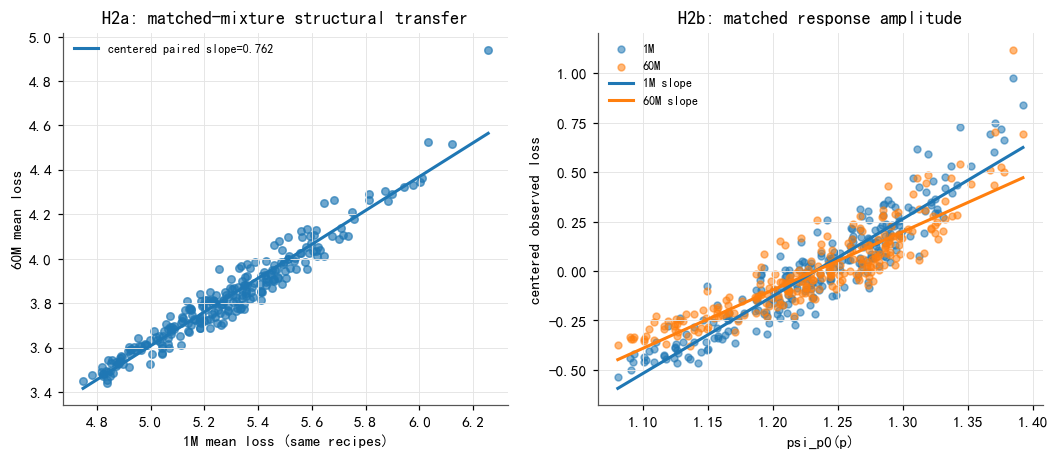

In [7]:
# ============ 4. Q1 -> Q2：matched 配比结构/幅度迁移 + 质量坐标桥 ============
DOM17=list(Q1['domain_order'])
assert set(DOM17)==set(Q1_FINAL['mixture_domain_Q'])==set(Q1_FINAL['risk_recipe_p'])
assert Q1_FINAL['quality_score_column']=='Q_res'
A_LOG=np.array([Q1['log_linear_model']['a_i'][d] for d in DOM17],float)
C0=float(Q1['log_linear_model']['intercept']);EPS_LOG=float(Q1['log_linear_model']['epsilon'])
P_REF=np.array([Q1['p_star_loglinear'][d] for d in DOM17],float)
P_RISK=np.array([Q1_FINAL['risk_recipe_p'][d] for d in DOM17],float)
Q17=pd.Series({d:float(Q1_FINAL['mixture_domain_Q'][d]) for d in DOM17})
Q_REF_A=float(P_REF@Q17.values);Q_BAR_A=float(P_RISK@Q17.values)
assert np.isclose(P_REF.sum(),1.0) and np.isclose(P_RISK.sum(),1.0)

def L_mix(p):
    p=np.asarray(p,float)
    return C0+np.sum(A_LOG*np.log(p+EPS_LOG),axis=-1)
L_REF=float(L_mix(P_REF))

def psi_p0(p):
    """附件 A 内部无量纲 structural bridge；不混用附件 B 的 E。"""
    return np.asarray(L_mix(p),float)/L_REF

res_ref=minimize(lambda p:float(L_mix(p)),P_REF,method='SLSQP',bounds=[(0,1)]*len(DOM17),
                 constraints=[{'type':'eq','fun':lambda p:np.sum(p)-1}],options={'ftol':1e-12,'maxiter':1000})
assert res_ref.success and float(L_mix(P_REF))-float(res_ref.fun)<1e-5

# ---------- 质量坐标桥：Q_A = Q_res -> Q_B = B6/B7 Q_score ----------
CQ_NOMINAL=1.0
CQ_SCENARIOS=(0.75,1.00,1.25)
def bridge_QA_to_QB(q_a,c_q=CQ_NOMINAL):
    q=np.asarray(q_a,float)
    return np.clip(1.0-float(c_q)*(1.0-q),0.0,1.0)
Q_REF_B=float(bridge_QA_to_QB(Q_REF_A));Q_BAR_B=float(bridge_QA_to_QB(Q_BAR_A))

# ---------- H2a/H2b：只使用问题一已用过的 A6-A9 matched recipes ----------
def _load_regmix_pair(base,mix_name,loss_name):
    mix=pd.read_csv(base/mix_name);loss=pd.read_csv(base/loss_name)
    mc=[c for c in mix.columns if c.startswith('train_')]
    lc=[c for c in loss.columns if c.endswith('_val_loss')]
    df=mix[['index']+mc].merge(loss[['index']+lc],on='index')
    P=df[mc].values.astype(float);P=P/P.sum(axis=1,keepdims=True)
    y=df[lc].values.astype(float).mean(axis=1)
    return df,P,y

def _match_mixtures(Pa,Pb,tol=1e-7):
    key=lambda row:tuple(np.round(row,7))
    lookup={key(row):j for j,row in enumerate(Pb)}
    pairs=[(i,lookup[key(row)]) for i,row in enumerate(Pa)
           if key(row) in lookup and np.max(np.abs(row-Pb[lookup[key(row)]]))<=tol]
    return np.asarray(pairs,dtype=int).reshape(-1,2)

# 优先读取 recipe-level 桥；若问题一旧接口尚未导出，则只读复核 A6-A9 原始表，不重拟合问题一模型。
_recipe_bridge=Q1_TABLE/'scale_mixture_response.csv'
if _recipe_bridge.exists():
    MR=pd.read_csv(_recipe_bridge)
    need={'scale','recipe_id','observed_mean_loss'}
    if not need.issubset(MR.columns):
        raise ValueError('scale_mixture_response.csv 缺少必要列: '+str(need-set(MR.columns)))
    m1=MR[MR.scale.astype(str).eq('1M_test')].copy();m60=MR[MR.scale.astype(str).eq('60M_test')].copy()
    mm=m1.merge(m60,on='recipe_id',suffixes=('_1M','_60M'))
    if 'psi_p0_1M' in mm.columns:
        z_raw=mm['psi_p0_1M'].values.astype(float)
    else:
        raise ValueError('recipe-level 桥必须包含 psi_p0；请运行最新版问题一桥接导出或允许本单元从 A6-A9 只读复核。')
    y1=mm.observed_mean_loss_1M.values.astype(float);y60=mm.observed_mean_loss_60M.values.astype(float)
    recipe_ids=mm.recipe_id.astype(str).values
else:
    A_REG_CANDS=[F_ROOT/'real_attachments'/'A_data_value'/'regmix_tables',
                 F_ROOT/'A_data_value'/'regmix_tables',
                 PROJECT_ROOT/'F题'/'real_attachments'/'A_data_value'/'regmix_tables']
    A_REG=next((p for p in A_REG_CANDS if (p/'test_mixture_1m.csv').exists()),None)
    if A_REG is None:
        raise FileNotFoundError('H2b 需要问题一 recipe-level 桥，或 real_attachments/A_data_value/regmix_tables/A6-A9 文件。')
    d1,P1,y1all=_load_regmix_pair(A_REG,'test_mixture_1m.csv','test_pile_loss_1m.csv')
    d60,P60,y60all=_load_regmix_pair(A_REG,'test_mixture_60m.csv','test_pile_loss_60m.csv')
    pairs=_match_mixtures(P1,P60)
    if len(pairs)<20: raise RuntimeError('1M/60M matched recipes 数量异常: %d'%len(pairs))
    Pm=P1[pairs[:,0]];y1=y1all[pairs[:,0]];y60=y60all[pairs[:,1]]
    z_raw=np.asarray(psi_p0(Pm),float)
    recipe_ids=np.array(['match_%04d'%i for i in range(len(pairs))])
    pd.DataFrame({'recipe_id':recipe_ids,'psi_p0':z_raw,'loss_1M':y1,'loss_60M':y60}).to_csv(
        TAB/'derived_matched_mixture_response_1M_60M.csv',index=False,encoding='utf-8-sig')

# 同一配比的排序结构。
RANK_1M60=float(stats.spearmanr(y1,y60)[0])
PEARSON_1M60=float(stats.pearsonr(y1,y60)[0])

# 同一 structural score 对两个尺度的中心化响应斜率；幅度比直接对应 psi_p0 的尺度传递强度。
z=z_raw-z_raw.mean();yc1=y1-y1.mean();yc60=y60-y60.mean()
den=float(z@z)
if den<=1e-15: raise RuntimeError('matched recipes 的 structural score 无变化，无法识别 H2b。')
B1_MIX=float((z@yc1)/den);B60_MIX=float((z@yc60)/den)
if B1_MIX*B60_MIX<=0: raise RuntimeError('1M/60M structural response slope 异号，H2b 的同向幅度迁移假设不成立。')
S60=float(B60_MIX/B1_MIX)
if S60<=0: raise RuntimeError('matched amplitude ratio 必须为正。')
GAMMA_P=float(-np.log(S60)/np.log(60.0))

# 直接中心化 Loss 的成对斜率作为独立一致性检查，而不是 gamma 的主估计量。
PAIR_SLOPE=float((yc1@yc60)/(yc1@yc1))
PAIR_R2=float(1.0-np.sum((yc60-PAIR_SLOPE*yc1)**2)/max(np.sum(yc60**2),1e-15))

# 成对 bootstrap：同一个 recipe 的 1M/60M 行始终一起重采样。
rng_gamma=np.random.default_rng(20260924);GAMMA_BOOT=[];S60_BOOT=[]
for _ in range(2000):
    ii=rng_gamma.integers(0,len(y1),len(y1))
    zb=z_raw[ii]-z_raw[ii].mean();a=y1[ii]-y1[ii].mean();b=y60[ii]-y60[ii].mean()
    dz=float(zb@zb)
    if dz<=1e-15: continue
    b1=float((zb@a)/dz);b60=float((zb@b)/dz)
    if b1*b60<=0: continue
    ss=b60/b1
    if ss>0 and np.isfinite(ss):
        S60_BOOT.append(ss);GAMMA_BOOT.append(-np.log(ss)/np.log(60.0))
GAMMA_BOOT=np.asarray(GAMMA_BOOT,float);S60_BOOT=np.asarray(S60_BOOT,float)
if len(GAMMA_BOOT)<500: raise RuntimeError('matched bootstrap 有效样本不足。')
GAMMA_CI=np.percentile(GAMMA_BOOT,[2.5,50,97.5]);S60_CI=np.percentile(S60_BOOT,[2.5,50,97.5])

N0=1e6
def g_scale(N,gamma=None):
    gamma=GAMMA_P if gamma is None else float(gamma)
    return (np.asarray(N,float)/N0)**(-gamma)

def psi_p(p,N=N0,gamma=None):
    return 1.0+g_scale(N,gamma)*(psi_p0(p)-1.0)

uniform=np.ones(len(DOM17))/len(DOM17)
assert np.isclose(float(psi_p(P_REF,N0)),1.0,atol=1e-12)

# 统一按“任务—指标”记录证据，不把 Spearman、RMSE、幅度斜率互相比较。
H2_STRUCTURE=pd.DataFrame([{
    'task':'mixture rank transfer','dataset':'matched 1M->60M','n':len(y1),
    'primary_metric':'Spearman','primary_value':RANK_1M60,
    'secondary_metric':'Pearson','secondary_value':PEARSON_1M60,
    'evidence_role':'matched structural transfer validation'}])
H2_AMPLITUDE=pd.DataFrame([{
    'task':'mixture amplitude transfer','dataset':'matched 1M->60M','n':len(y1),
    'b_1M':B1_MIX,'b_60M':B60_MIX,'s_60M_over_1M':S60,
    's_ci_low':S60_CI[0],'s_ci_high':S60_CI[2],
    'gamma_p_local':GAMMA_P,'gamma_ci_low':GAMMA_CI[0],'gamma_ci_high':GAMMA_CI[2],
    'paired_loss_slope':PAIR_SLOPE,'paired_loss_centered_R2':PAIR_R2}])
H2_STRUCTURE.to_csv(TAB/'h2_structure_transfer_evidence.csv',index=False,encoding='utf-8-sig')
H2_AMPLITUDE.to_csv(TAB/'h2_matched_amplitude_transfer.csv',index=False,encoding='utf-8-sig')
pd.DataFrame({'gamma_boot':GAMMA_BOOT,'s60_boot':S60_BOOT}).to_csv(TAB/'h2_matched_gamma_bootstrap.csv',index=False,encoding='utf-8-sig')

# 1B 没有 matched recipes，只读取问题一固定检验的排序表现作为非匹配尺度证据。
H2_NONMATCHED=pd.DataFrame()
_sci_eval_path=Q1_TABLE/'sci_vs_scm.csv'
if _sci_eval_path.exists():
    H2_NONMATCHED=pd.read_csv(_sci_eval_path)
    H2_NONMATCHED.to_csv(TAB/'h2_nonmatched_scale_rank_check.csv',index=False,encoding='utf-8-sig')

# 问题一稳定 SCI 交互。
SCI_SELECTED=[]
_sci_path=Q1_TABLE/'sci_stability_selection.csv'
if _sci_path.exists():
    _stb=pd.read_csv(_sci_path)
    SCI_SELECTED=_stb.loc[_stb['selected'].astype(str).str.lower().eq('true'),'interaction'].tolist()

print('p_ref structural loss=%.5f; p_risk structural loss=%.5f; psi_p0(risk)=%.5f' %
      (L_REF,float(L_mix(P_RISK)),float(psi_p0(P_RISK))))
print('质量坐标桥: Q_A(ref/risk)=%.4f/%.4f -> nominal Q_B=%.4f/%.4f (c_Q=1)' %
      (Q_REF_A,Q_BAR_A,Q_REF_B,Q_BAR_B))
print('H2a matched 1M->60M: n=%d, Spearman=%.4f, Pearson=%.4f' % (len(y1),RANK_1M60,PEARSON_1M60))
print('H2b structural response: b_1M=%.5f, b_60M=%.5f, s60=%.4f, local gamma_p=%.4f' %
      (B1_MIX,B60_MIX,S60,GAMMA_P))
print('matched bootstrap: s60 2.5/50/97.5%%=',np.round(S60_CI,4),
      '; gamma_p=',np.round(GAMMA_CI,4))
print('Q1 稳定 SCI 交互=',SCI_SELECTED)
display(H2_STRUCTURE);display(H2_AMPLITUDE)

fig,axs=plt.subplots(1,2,figsize=(11.5,4.4))
axs[0].scatter(y1,y60,s=24,alpha=.65)
xx=np.linspace(y1.min(),y1.max(),100)
axs[0].plot(xx,y60.mean()+PAIR_SLOPE*(xx-y1.mean()),lw=2,label='centered paired slope=%.3f'%PAIR_SLOPE)
axs[0].set(xlabel='1M mean loss (same recipes)',ylabel='60M mean loss',title='H2a: matched-mixture structural transfer')
axs[0].legend(frameon=False,fontsize=8)
axs[1].scatter(z_raw,y1-y1.mean(),s=20,alpha=.55,label='1M')
axs[1].scatter(z_raw,y60-y60.mean(),s=20,alpha=.55,label='60M')
zg=np.linspace(z_raw.min(),z_raw.max(),100);zc=zg-z_raw.mean()
axs[1].plot(zg,B1_MIX*zc,lw=2,label='1M slope')
axs[1].plot(zg,B60_MIX*zc,lw=2,label='60M slope')
axs[1].set(xlabel='psi_p0(p)',ylabel='centered observed loss',title='H2b: matched response amplitude')
axs[1].legend(frameon=False,fontsize=8)
savefig('fig06_h2_matched_structure_and_amplitude.png');plt.show()


## 5. 模块化可分离广义标度律：合成、边际效用与替代关系

### 5.1 广义标度律与可识别边界

附件中不存在一个实验同时独立改变 $N,D,Q,\mathbf p$，尤其缺少 $Q\times\mathbf p$ 的联合干预，因此不能从数据中识别任意四维交互。为保持模型可辨识，采用**模块化乘法可分离**结构：
$$\boxed{
L(N,D,Q_A,\mathbf p)
=E+R(N,D)\,\psi_Q[T(Q_A;c_Q)]\,\psi_p(\mathbf p;N)
},$$
其中
$$R(N,D)=AN^{-\alpha}+BD^{-\beta},$$
$$T(Q_A;c_Q)=\operatorname{clip}\{1-c_Q(1-Q_A),0,1\},$$
$$\psi_Q(Q_B)=1+\kappa(1-Q_B),$$
$$\psi_p(\mathbf p;N)=1+\left(\frac N{N_0}\right)^{-\gamma_p}\left[\psi_{p,0}(\mathbf p)-1\right].$$

该乘法结构是跨附件连接所需的**最小可辨识假设**，并不意味着真实训练过程中不存在质量—配比交互。中心情景取 $c_Q=1$，并用 $c_Q=0.75/1.25$ 检验质量量表桥接的敏感性。

当 $Q_A=1,\mathbf p=\mathbf p_{\rm ref}$ 时模型退化为经典 $N$–$D$ 标度律。$\gamma_p$ 由 1M↔60M matched recipes 的响应幅度比识别；将其用于 60M 以上属于外推，并在第 6–7 节通过 bootstrap 区间传播不确定性。

### 5.2 轴向等效资源、边际效用与弹性

令
$$\Phi=\psi_Q[T(Q_A;c_Q)]\psi_p(\mathbf p;N).$$
分别沿参数轴、数据轴定义
$$\boxed{N_{\rm eq}^{(N)}=N\Phi^{-1/\alpha}},\qquad
\boxed{D_{\rm eq}^{(D)}=D\Phi^{-1/\beta}.$$
它们表示**在标度律单轴换算意义下**的等效规模，不是模型真实参数量、真实 token 数，也不是同时满足相同算力的唯一资源配置。

令 $g(N)=(N/N_0)^{-\gamma_p}$、$b(\mathbf p)=\psi_{p,0}(\mathbf p)$，则
$$\psi_p=1+g(N)[b(\mathbf p)-1],\qquad
\frac{\partial\log\psi_p}{\partial N}
=-\frac{\gamma_p g(N)[b(\mathbf p)-1]}{N\psi_p}.$$
在坐标桥未发生截断的内部区间，$dQ_B/dQ_A=c_Q$，故
$$\frac{\partial L}{\partial N}
=-\alpha AN^{-\alpha-1}\Phi+R\Phi\frac{\partial\log\psi_p}{\partial N},$$
$$\frac{\partial L}{\partial D}=-\beta BD^{-\beta-1}\Phi,$$
$$\frac{\partial L}{\partial Q_A}=-\kappa c_Q R(N,D)\psi_p.$$
代码用中心差分核验三个解析导数。

### 5.3 质量与模型规模的替代条件

固定 $D,\mathbf p$，将问题一质量从 $Q_A$ 提高到 $Q_A'>Q_A$。当实证得到的 $\gamma_p\ge0$ 时，$N'\to\infty$ 有
$$L_\infty=E+BD^{-\beta}\psi_Q[T(Q_A';c_Q)]\,p_\infty,$$
其中 $\gamma_p>0$ 时 $p_\infty=1$，$\gamma_p=0$ 时 $p_\infty=\psi_{p,0}(\mathbf p)$。若
$$\boxed{L(N,D,Q_A,\mathbf p)>L_\infty}$$
且 $\partial L/\partial N<0$，则存在唯一有限 $N'$ 满足
$$L(N',D,Q_A',\mathbf p)=L(N,D,Q_A,\mathbf p).$$
随后用 Brent 求根得到 $N'/N$。这里的 $N'/N$ 是“提高质量后维持同一 Loss 所需的参数倍率”；若要回答反方向“低质量需要放大多少参数”，必须另解反向方程，不能简单取倒数。

### 5.4 单纯形上的领域再分配与交互

领域配比满足
$$\sum_i p_i=1,$$
因此允许的局部变化必须位于单纯形切空间。若从域 $k$ 向域 $i$ 转移微小份额 $\delta$：
$$p_i\to p_i+\delta,\qquad p_k\to p_k-\delta,$$
则
$$\boxed{\Delta_{i\leftarrow k}=\frac{dL}{d\delta}=\frac{\partial L}{\partial p_i}-\frac{\partial L}{\partial p_k}}.$$
$\Delta_{i\leftarrow k}<0$ 表示从 $k$ 向 $i$ 转移少量份额会降低预测 Loss；$\Delta_{i\leftarrow k}>0$ 表示会提高 Loss。该量替代无约束空间中的 $-g_i/g_k$，严格满足 $\sum_i dp_i=0$。

非加性交互仍直接读取问题一已输出的二阶交互表，不在本问重新拟合。$b_{ik}<0$ 只称为互补/协同候选，$b_{ik}>0$ 只称为替代/拮抗候选，并明确其为代理模型的局部曲率证据而非因果结论。

### 5.5 配比尺度感知的计算最优前沿

在 $C=6ND$ 下数值求解 $N^\star,D^\star$。由于 $\psi_Q[T(Q_A;c_Q)]$ 对 $N,D$ 是正的常数因子，**固定 $\mathbf p$ 时改变 $Q_A$ 只改变最优 Loss 水平，不单独改变 $N^\star:D^\star$**；真正改变 $N$–$D$ 最优分配的是 $\psi_p(\mathbf p;N)$ 中的尺度耦合。因此本问称其为“配比尺度感知 Compute-Optimal Frontier”，而非把质量项误解释为会单独移动固定配比下的最优比例。


广义模型参数: kappa=0.4597, matched local gamma_p=0.0686, nominal c_Q=1.00
证据指标按任务分栏记录，不把 RMSE、Spearman、幅度斜率横向比较。


,task,dataset,evidence_role,primary_metric,primary_value,secondary_metric,secondary_value
0,quality absolute prediction,"B7 novel Q_B={0.5,0.7}",outer validation,RMSE,0.0467,R2,0.9789
1,mixture rank transfer,matched 1M->60M,matched structural validation,Spearman,0.9658,Pearson,0.9671
2,mixture amplitude transfer,matched 1M->60M,matched amplitude calibration,s60=b60/b1,0.7550,local gamma_p,0.0686


域间二阶交互证据（候选关系，不作因果解释）:


,域i,域k,b_ik,relation,stable_SCI_pair
0,pubmed_central,hackernews,-0.0025,complement/synergy candidate,False
1,wikipedia_en,enron_emails,-0.0022,complement/synergy candidate,False
2,philpapers,pile_cc,-0.0021,complement/synergy candidate,False
3,ubuntu_irc,pubmed_abstracts,-0.0020,complement/synergy candidate,False
4,freelaw,dm_mathematics,-0.0019,complement/synergy candidate,False
5,nih_exporter,philpapers,-0.0017,complement/synergy candidate,False
11,wikipedia_en,pile_cc,0.0047,substitute/antagonism candidate,False
10,pubmed_central,pubmed_abstracts,0.0049,substitute/antagonism candidate,False
9,enron_emails,pile_cc,0.0050,substitute/antagonism candidate,False
8,stackexchange,pile_cc,0.0058,substitute/antagonism candidate,False


,reference,Q_A,Q_B,Phi,D_axis_equiv,N_axis_equiv,eps_N,eps_D,eps_Q_A
0,Pythia-1B @ 300B tokens,0.6223,0.6223,1.2006,156133702448.9204,607491721.9603,-0.0596,-0.0350,-0.0729
1,Pythia-1B @ 300B tokens,0.8000,0.8000,1.1170,202024394215.5762,751047742.8149,-0.0566,-0.0333,-0.0957
2,Pythia-1B @ 300B tokens,1.0000,1.0000,1.0230,276610796371.6129,972774429.6707,-0.0531,-0.0312,-0.0000
3,classic-opt @ C=1e22,0.6223,0.6223,1.1978,169558571588.1211,3034134096.4731,-0.0374,-0.0370,-0.0588
4,classic-opt @ C=1e22,0.8000,0.8000,1.1144,219395090053.3802,3751128586.9056,-0.0354,-0.0351,-0.0769
5,classic-opt @ C=1e22,1.0000,1.0000,1.0206,300394666769.4462,4858548616.4598,-0.0330,-0.0327,-0.0000
6,LLaMA-7B @ 1T tokens,0.6223,0.6223,1.1973,525602265596.7858,4122209527.3725,-0.0353,-0.0283,-0.0498
7,LLaMA-7B @ 1T tokens,0.8000,0.8000,1.1139,680086859147.2977,5096326499.6480,-0.0333,-0.0267,-0.0649
8,LLaMA-7B @ 1T tokens,1.0000,1.0000,1.0202,931171547084.8762,6600880105.8772,-0.0310,-0.0249,-0.0000
9,classic-opt @ C=1e24,0.6223,0.6223,1.1945,2140094767172.7104,24463718880.9563,-0.0209,-0.0208,-0.0330


,reference,Q_A,delta_Q_A,lowQ_required_N_multiplier,exists,proof_applicable,monotone_at_root,N_equiv,N_multiplier,target_loss,limiting_loss,Q_A_new,Q_B_new
0,Pythia-1B @ 300B tokens,0.5000,0.1000,1.2139,True,True,True,861200310.5829,0.8281,2.4454,1.9873,0.6000,0.6000
1,Pythia-1B @ 300B tokens,0.7000,0.1000,1.2338,True,True,True,848088189.6349,0.8155,2.3889,1.9642,0.8000,0.8000
2,Pythia-1B @ 300B tokens,0.6223,0.1000,1.2256,True,True,True,853400689.7196,0.8206,2.4109,1.9732,0.7223,0.7223
3,classic-opt @ C=1e22,0.5000,0.1000,1.2863,True,True,True,4055748658.4365,0.7862,2.2531,1.9812,0.6000,0.6000
4,classic-opt @ C=1e22,0.7000,0.1000,1.3140,True,True,True,3977901754.1642,0.7711,2.2110,1.9586,0.8000,0.8000
5,classic-opt @ C=1e22,0.6223,0.1000,1.3027,True,True,True,4009391467.4646,0.7772,2.2274,1.9674,0.7223,0.7223
6,LLaMA-7B @ 1T tokens,0.5000,0.1000,1.2518,True,True,True,5637783636.1213,0.8054,2.1441,1.9022,0.6000,0.6000
7,LLaMA-7B @ 1T tokens,0.7000,0.1000,1.2757,True,True,True,5539908027.0449,0.7914,2.1101,1.8857,0.8000,0.8000
8,LLaMA-7B @ 1T tokens,0.6223,0.1000,1.2659,True,True,True,5579528998.2871,0.7971,2.1233,1.8921,0.7223,0.7223
9,classic-opt @ C=1e24,0.5000,0.1000,1.2867,True,True,True,32434620437.0850,0.7860,1.9669,1.8335,0.6000,0.6000


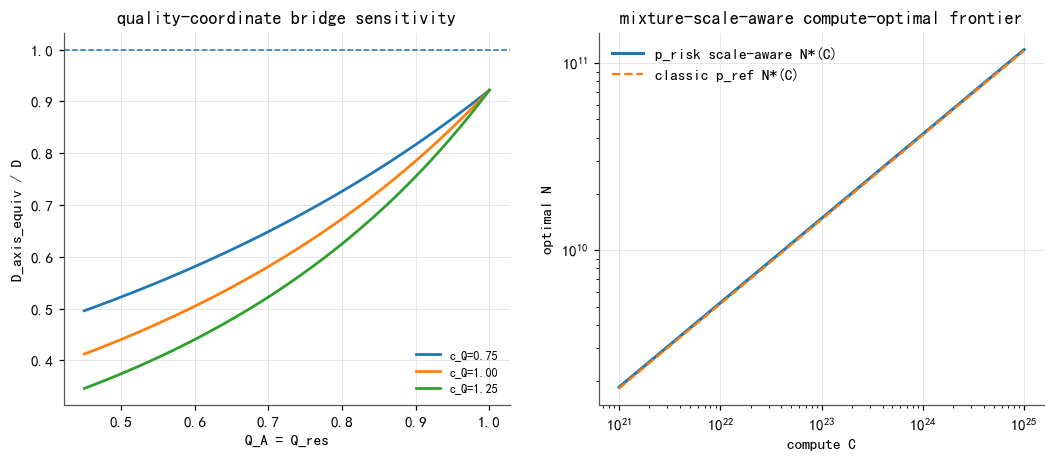

In [8]:
# ============ 5. 模块化可分离 SAED：轴向等效资源、单纯形再分配、替代条件 ============
def saed_components(N,D,Q_A=1.0,p=None,kappa=None,gamma=None,c_q=CQ_NOMINAL):
    p=P_REF if p is None else np.asarray(p,float)
    q_b=bridge_QA_to_QB(Q_A,c_q)
    phiq=psi_Q(q_b,KAPPA if kappa is None else kappa)
    phip=psi_p(p,N,GAMMA_P if gamma is None else gamma)
    Phi=np.asarray(phiq)*np.asarray(phip)
    tn=TH['A']*np.asarray(N,float)**(-TH['alpha'])*Phi
    td=TH['B']*np.asarray(D,float)**(-TH['beta'])*Phi
    return Phi,tn,td,phiq,phip,q_b

def L_general(N,D,Q_A=1.0,p=None,kappa=None,gamma=None,c_q=CQ_NOMINAL):
    Phi,TN,TD,_,_,_=saed_components(N,D,Q_A,p,kappa,gamma,c_q)
    return TH['E']+TN+TD

def axis_equivalent_resources(N,D,Q_A=1.0,p=None,c_q=CQ_NOMINAL):
    Phi,_,_,_,_,q_b=saed_components(N,D,Q_A,p,c_q=c_q)
    return (np.asarray(N,float)*Phi**(-1.0/TH['alpha']),
            np.asarray(D,float)*Phi**(-1.0/TH['beta']),Phi,q_b)

def derivatives(N,D,Q_A,p=None,c_q=CQ_NOMINAL):
    N=float(N);D=float(D);Q_A=float(Q_A);p=P_REF if p is None else np.asarray(p,float)
    Phi,TN,TD,phiq,phip,q_b=saed_components(N,D,Q_A,p,c_q=c_q)
    Phi=float(Phi);TN=float(TN);TD=float(TD);phiq=float(phiq);phip=float(phip);q_b=float(q_b)
    base=float(psi_p0(p));g=float(g_scale(N))
    dlogphi_dN=(-GAMMA_P*g*(base-1.0)/N)/phip
    dN=-TH['alpha']*TN/N+(TN+TD)*dlogphi_dN
    dD=-TH['beta']*TD/D
    # clip 内部导数；若桥接已经饱和到 0/1，局部导数按 0 处理。
    raw_qb=1.0-float(c_q)*(1.0-Q_A);dqb_dqa=float(c_q) if 0.0<raw_qb<1.0 else 0.0
    dQ=-(TN+TD)*float(h_q(q_b))*dqb_dqa
    L=float(TH['E']+TN+TD)
    return {'L':L,'Phi':Phi,'Q_B':q_b,'dL_dN':dN,'dL_dD':dD,'dL_dQ_A':dQ,
            'MU_N':-dN,'MU_D':-dD,'MU_Q_A':-dQ,
            'eps_N':N*dN/L,'eps_D':D*dD/L,'eps_Q_A':Q_A*dQ/L}

# 解析导数数值核验。
N_CHECK,D_CHECK,Q_CHECK=1.04e9,3e11,.7
for var,step in [('N',1e5),('D',1e7),('Q_A',1e-6)]:
    args=[N_CHECK,D_CHECK,Q_CHECK];i={'N':0,'D':1,'Q_A':2}[var]
    plus=args.copy();minus=args.copy();plus[i]+=step;minus[i]-=step
    num=(L_general(*plus,P_RISK)-L_general(*minus,P_RISK))/(2*step)
    ana=derivatives(*args,P_RISK)['dL_d'+var]
    assert np.isclose(num,ana,rtol=3e-5,atol=1e-12),(var,num,ana)
assert np.isclose(L_general(N_CHECK,D_CHECK,1.0,P_REF),L_classic(N_CHECK,D_CHECK,TH),rtol=1e-12)

# ---------- 单纯形上的领域成对再分配效应 ----------
def dL_dp_unconstrained(N,D,Q_A,p,c_q=CQ_NOMINAL):
    p=np.asarray(p,float);Phi,TN,TD,_,phip,_=saed_components(N,D,Q_A,p,c_q=c_q)
    g=float(g_scale(N));dr=(A_LOG/(p+EPS_LOG))/L_REF
    dlogphi=g*dr/float(phip)
    return (float(TN)+float(TD))*dlogphi

grad=dL_dp_unconstrained(1e9,3e11,Q_BAR_A,uniform)
# 行 i=接受份额的域，列 k=让出份额的域；负值表示 k -> i 会降低 Loss。
REALLOC=grad[:,None]-grad[None,:]
REALLOC_DF=pd.DataFrame(REALLOC,index=DOM17,columns=DOM17)
REALLOC_DF.to_csv(TAB/'saed_pairwise_reallocation_effect_uniform.csv',encoding='utf-8-sig')
# 反对称性是单纯形方向导数的必要校验。
assert np.allclose(REALLOC,-REALLOC.T,atol=1e-12) and np.allclose(np.diag(REALLOC),0,atol=1e-12)

# Q1 二阶交互证据：不重新拟合，只读取问题一已经输出的结果。
INTERACTION_EVIDENCE=pd.DataFrame();_int_path=Q1_TABLE/'domain_interactions.csv'
if _int_path.exists():
    _ints=pd.read_csv(_int_path);_ints=_ints[[c for c in _ints.columns if not str(c).startswith('Unnamed')]]
    if {'域i','域k','b_ik'}.issubset(_ints.columns):
        _ints['relation']=np.where(_ints.b_ik<0,'complement/synergy candidate','substitute/antagonism candidate')
        _ints['stable_SCI_pair']=False
        for s in SCI_SELECTED:
            parts=[x.strip() for x in str(s).split('×',1)]
            if len(parts)==2:
                m=((_ints['域i']==parts[0])&(_ints['域k']==parts[1]))|((_ints['域i']==parts[1])&(_ints['域k']==parts[0]))
                _ints.loc[m,'stable_SCI_pair']=True
        keep=pd.concat([_ints.nsmallest(6,'b_ik'),_ints.nlargest(6,'b_ik'),_ints[_ints.stable_SCI_pair]],ignore_index=True).drop_duplicates()
        INTERACTION_EVIDENCE=keep.sort_values('b_ik')
        INTERACTION_EVIDENCE.to_csv(TAB/'saed_domain_interaction_evidence.csv',index=False,encoding='utf-8-sig')

# ---------- 质量 -> 参数规模替代：存在性 + 唯一性 + 数值解 ----------
def p_limit_at_infinity(p,gamma=None):
    ga=GAMMA_P if gamma is None else float(gamma)
    if ga>1e-12: return 1.0
    if abs(ga)<=1e-12: return float(psi_p0(p))
    return np.nan  # gamma<0 时无有限的配比幅度极限，不使用该解析 floor。

def substitution_floor(D,Q_A_new,p=None,c_q=CQ_NOMINAL,gamma=None):
    p=P_REF if p is None else np.asarray(p,float);plim=p_limit_at_infinity(p,gamma)
    if not np.isfinite(plim): return np.nan
    qb=float(bridge_QA_to_QB(Q_A_new,c_q))
    return float(TH['E']+TH['B']*float(D)**(-TH['beta'])*float(psi_Q(qb))*plim)

def N_equiv_with_condition(N,D,Q_A,dQ=.1,p=None,c_q=CQ_NOMINAL):
    p=P_REF if p is None else np.asarray(p,float)
    target=float(L_general(N,D,Q_A,p,c_q=c_q));q2=min(float(Q_A)+float(dQ),1.0)
    floor=substitution_floor(D,q2,p,c_q)
    proof_applicable=bool(GAMMA_P>=-1e-12 and np.isfinite(floor))
    if proof_applicable and target<=floor+1e-12:
        return {'exists':False,'proof_applicable':True,'N_equiv':np.nan,'N_multiplier':np.nan,
                'target_loss':target,'limiting_loss':floor,'Q_A_new':q2,'Q_B_new':float(bridge_QA_to_QB(q2,c_q))}
    f=lambda x:float(L_general(x,D,q2,p,c_q=c_q))-target
    lo=max(float(N)*1e-8,1e3);hi=max(float(N),1e4)
    while f(hi)>0 and hi<1e18: hi*=10
    if f(lo)*f(hi)>0:
        return {'exists':False,'proof_applicable':proof_applicable,'N_equiv':np.nan,'N_multiplier':np.nan,
                'target_loss':target,'limiting_loss':floor,'Q_A_new':q2,'Q_B_new':float(bridge_QA_to_QB(q2,c_q))}
    n2=brentq(f,lo,hi,maxiter=300)
    # 经验 gamma>=0 且 psi_p0>=1 时导数应为负；再做数值验证。
    monotone=float(derivatives(max(n2,1e3),D,q2,p,c_q)['dL_dN'])<0
    return {'exists':True,'proof_applicable':proof_applicable,'monotone_at_root':bool(monotone),
            'N_equiv':float(n2),'N_multiplier':float(n2/N),'target_loss':target,'limiting_loss':floor,
            'Q_A_new':q2,'Q_B_new':float(bridge_QA_to_QB(q2,c_q))}

# 反方向“低质量需要多少参数才能追平高质量”单独求解，不用 1/(N'/N) 代替。
def N_required_lowQ_to_match_highQ(N,D,Q_A,dQ=.1,p=None,c_q=CQ_NOMINAL):
    p=P_REF if p is None else np.asarray(p,float);q_hi=min(float(Q_A)+float(dQ),1.0)
    target=float(L_general(N,D,q_hi,p,c_q=c_q))
    f=lambda x:float(L_general(x,D,Q_A,p,c_q=c_q))-target
    lo=max(float(N)*1e-3,1e3);hi=max(float(N),1e4)
    while f(hi)>0 and hi<1e18: hi*=10
    if f(lo)*f(hi)>0: return np.nan
    return float(brentq(f,lo,hi,maxiter=300)/float(N))

# ---------- 配比尺度感知 compute-optimal frontier ----------
def N_opt_saed(C,Q_A=1.0,p=None,c_q=CQ_NOMINAL):
    p=P_REF if p is None else np.asarray(p,float);C=float(C)
    lo=np.log(max(1e5,np.sqrt(C/6)/1e4));hi=np.log(min(1e15,np.sqrt(C/6)*1e4))
    obj=lambda z:float(L_general(np.exp(z),C/(6*np.exp(z)),Q_A,p,c_q=c_q))
    r=minimize(lambda z:obj(float(z[0])),[(lo+hi)/2],method='L-BFGS-B',bounds=[(lo,hi)])
    return float(np.exp(r.x[0]))
def D_opt_saed(C,Q_A=1.0,p=None,c_q=CQ_NOMINAL):
    n=N_opt_saed(C,Q_A,p,c_q);return float(C/(6*n))

# 固定 p 时 Q 只乘以正的常数，因此不应改变 N:D 最优比例。
for _C in (1e22,1e24):
    n1=N_opt_saed(_C,Q_BAR_A,P_RISK);n2=N_opt_saed(_C,.8,P_RISK)
    assert np.isclose(n1,n2,rtol=2e-4),('固定 p 下 Q 不应改变 N_opt',_C,n1,n2)

REF=[('Pythia-1B @ 300B tokens',1.04e9,3e11),('classic-opt @ C=1e22',float(N_opt(1e22)),float(D_opt(1e22))),
     ('LLaMA-7B @ 1T tokens',7e9,1e12),('classic-opt @ C=1e24',float(N_opt(1e24)),float(D_opt(1e24)))]
rows=[];sub=[]
for name,n,d in REF:
    for qA in (Q_BAR_A,.8,1.0):
        ne,deq,phi,qb=axis_equivalent_resources(n,d,qA,P_RISK)
        rows.append({'reference':name,'N':n,'D':d,'Q_A':qA,'Q_B':float(qb),
                     'N_axis_equiv':float(ne),'D_axis_equiv':float(deq),'Phi':float(phi),
                     **derivatives(n,d,qA,P_RISK)})
    for qA in (.5,.7,Q_BAR_A):
        ans=N_equiv_with_condition(n,d,qA,.1,P_RISK)
        reverse=N_required_lowQ_to_match_highQ(n,d,qA,.1,P_RISK)
        sub.append({'reference':name,'Q_A':qA,'delta_Q_A':.1,'lowQ_required_N_multiplier':reverse,**ans})
ELAS=pd.DataFrame(rows);SUB=pd.DataFrame(sub)
ELAS.to_csv(TAB/'saed_axis_equivalent_resources_and_elasticities.csv',index=False,encoding='utf-8-sig')
SUB.to_csv(TAB/'saed_quality_parameter_substitution.csv',index=False,encoding='utf-8-sig')

# 按任务分开记录证据，禁止跨任务比较不同量纲指标。
EVIDENCE_BY_TASK=pd.DataFrame([
 {'task':'quality absolute prediction','dataset':'B7 novel Q_B={0.5,0.7}','evidence_role':'outer validation',
  'primary_metric':'RMSE','primary_value':QUALITY_RMSE,'secondary_metric':'R2','secondary_value':QUALITY_R2},
 {'task':'mixture rank transfer','dataset':'matched 1M->60M','evidence_role':'matched structural validation',
  'primary_metric':'Spearman','primary_value':RANK_1M60,'secondary_metric':'Pearson','secondary_value':PEARSON_1M60},
 {'task':'mixture amplitude transfer','dataset':'matched 1M->60M','evidence_role':'matched amplitude calibration',
  'primary_metric':'s60=b60/b1','primary_value':S60,'secondary_metric':'local gamma_p','secondary_value':GAMMA_P}
])
EVIDENCE_BY_TASK.to_csv(TAB/'saed_evidence_by_task.csv',index=False,encoding='utf-8-sig')

print('广义模型参数: kappa=%.4f, matched local gamma_p=%.4f, nominal c_Q=%.2f' % (KAPPA,GAMMA_P,CQ_NOMINAL))
print('证据指标按任务分栏记录，不把 RMSE、Spearman、幅度斜率横向比较。')
display(EVIDENCE_BY_TASK)
if len(INTERACTION_EVIDENCE):
    print('域间二阶交互证据（候选关系，不作因果解释）:');display(INTERACTION_EVIDENCE)
display(ELAS[['reference','Q_A','Q_B','Phi','D_axis_equiv','N_axis_equiv','eps_N','eps_D','eps_Q_A']]);display(SUB)

fig,axs=plt.subplots(1,2,figsize=(11.5,4.4))
qq=np.linspace(.45,1,100)
for cq in CQ_SCENARIOS:
    axs[0].plot(qq,[axis_equivalent_resources(1e9,3e11,q,P_RISK,cq)[1]/3e11 for q in qq],lw=1.8,label='c_Q=%.2f'%cq)
axs[0].axhline(1,ls='--',lw=1);axs[0].set(xlabel='Q_A = Q_res',ylabel='D_axis_equiv / D',title='quality-coordinate bridge sensitivity');axs[0].legend(frameon=False,fontsize=8)
Cs=np.logspace(21,25,50)
axs[1].plot(Cs,[N_opt_saed(c,Q_BAR_A,P_RISK) for c in Cs],lw=2,label='p_risk scale-aware N*(C)')
axs[1].plot(Cs,[N_opt(c) for c in Cs],ls='--',lw=1.5,label='classic p_ref N*(C)')
axs[1].set_xscale('log');axs[1].set_yscale('log');axs[1].set(xlabel='compute C',ylabel='optimal N',title='mixture-scale-aware compute-optimal frontier');axs[1].legend(frameon=False)
savefig('fig07_saed_axis_equivalent_resource_frontier.png');plt.show()


## 6. 百亿参数以上的外推与不确定性

**B10 的性质**。B10 的 100B–10000B Loss 是估算值，用同一标度律代入即可复现，因此其拟合度只作为内部一致性检查；B9 只提供真实大模型的参数量与 token 元数据，用于大尺度位置参考，不根据其 $D/N$ 与经典前沿之差给出未经题目支持的“过量/不足训练”硬结论。

**跨族指数不确定性**。B1 的极小残差不能代表跨模型族的不确定性。B4 按模型族、B5 按**文献来源**进行 cluster bootstrap，在
$$L_f=E_f+s_fR_{\alpha,\beta}(N,D)$$
结构下重新识别 $\alpha,\beta$。因此 H1 的结论是“规模骨架具有迁移性”，而不是“所有来源严格共享同一指数”。B1 指数用于中心模型，跨族重估分布用于外推敏感性。

**物理约束重标定**。每组 bootstrap 指数 $(\alpha,\beta)$ 回代 B1 时，使用带边界的线性最小二乘重新估计 $(E,A,B)$，强制
$$E\ge0,\qquad A\ge0,\qquad B\ge0,$$
避免极端指数样本生成非物理标度律并破坏单调性。

**质量、配比与坐标桥的不确定性**。$\kappa$ 来自 B6 的 $(N,D)$ cluster bootstrap；$\gamma_p$ 来自 matched 1M↔60M recipe 的成对 bootstrap；$c_Q\in\{0.75,1,1.25\}$ 作为跨附件质量坐标桥的场景不确定性。将这些因素与跨族 $(\alpha,\beta)$ 一并传播至百亿参数以上预测，得到联合**敏感性带**而不是把它误称为完全统计独立的置信区间。

对 $\gamma_p$ 的证据边界特别说明：它只在 1M↔60M matched recipes 上被直接识别；应用到 1B、10B、70B 属于模型外推，必须与其 bootstrap 区间共同报告。


B10 估算 Loss 与经典定律: RMSE=0.0011, max|err|=0.0052, Spearman=1.000（B10 非独立证据）


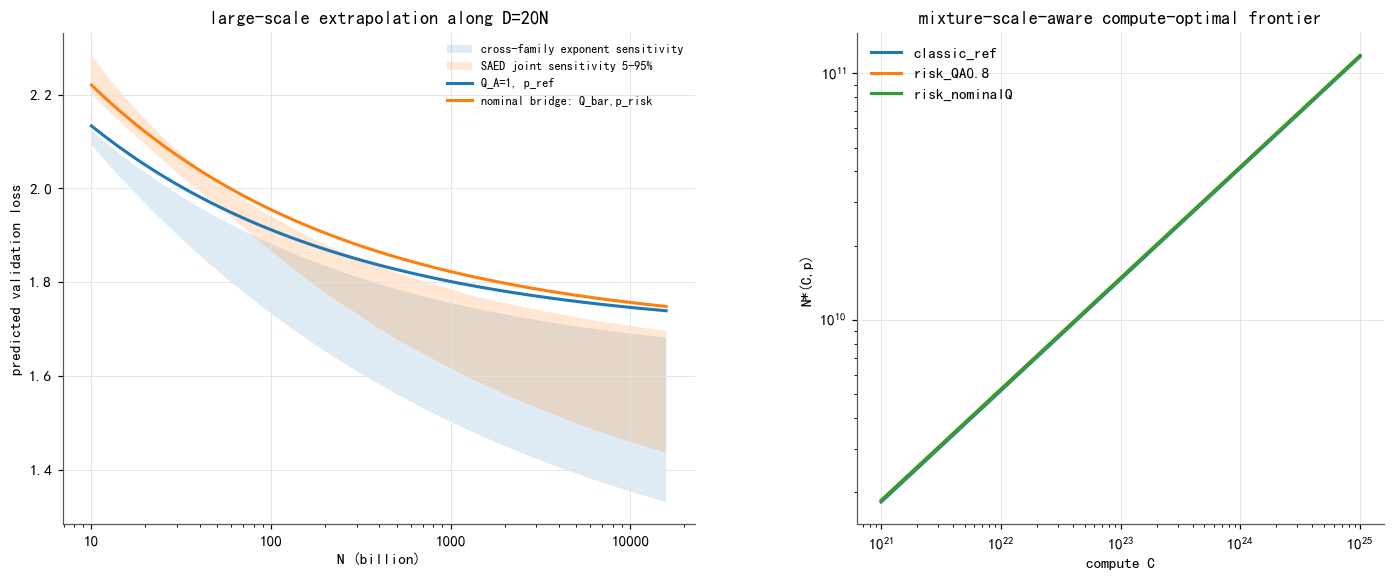

跨族结构重估: alpha=0.283 beta=0.252; sensitivity interval alpha=[0.197 0.293] beta=[0.179 0.28 ]
matched gamma_p bootstrap= [0.0574 0.0691 0.079 ] kappa(B6 cluster) CI= [0.4378 0.4873] c_Q scenarios= (0.75, 1.0, 1.25)


In [9]:
# ============ 6. 跨族指数 + matched gamma + Q坐标桥 的联合敏感性外推 ============
B10['pred']=L_classic(B10.N,B10.D,TH)
print('B10 估算 Loss 与经典定律: RMSE=%.4f, max|err|=%.4f, Spearman=%.3f（B10 非独立证据）' %
      (rmse(B10.val_loss,B10.pred),(B10.val_loss-B10.pred).abs().max(),stats.spearmanr(B10.val_loss,B10.pred)[0]))
B9c=B9.dropna(subset=['N_params_B','D_tokens_B']).copy();B9c=B9c[B9c.D_tokens_B>0]
B9c['N']=B9c.N_params_B*1e9;B9c['D']=B9c.D_tokens_B*1e9;B9c['C_6ND']=6*B9c.N*B9c.D
B9c['D_over_N']=B9c.D/B9c.N;B9c['classic_L']=L_classic(B9c.N,B9c.D,TH)
B9c['saed_L_risk_nominal_bridge']=L_general(B9c.N,B9c.D,Q_BAR_A,P_RISK)

# B4 按 family；B5 按文献 source 做 cluster bootstrap，与正文口径严格一致。
CF=pd.concat([B4.assign(grp='B4:'+B4.family.astype(str))[['grp','N','D','val_loss']],
              B5.assign(grp='B5:'+B5.source.astype(str))[['grp','N','D','val_loss']]],ignore_index=True)
def sse_exp(th,df):
    al,be=th;R=TH['A']*df.N.values**(-al)+TH['B']*df.D.values**(-be);L=df.val_loss.values;g=df.grp.values;pred=np.zeros_like(L)
    for key in np.unique(g):
        m=g==key
        if m.sum()>=3:
            X=np.column_stack([np.ones(m.sum()),R[m]]);c=np.linalg.lstsq(X,L[m],rcond=None)[0];pred[m]=X@c
        else: pred[m]=(L[m]-R[m]).mean()+R[m]
    return ((L-pred)**2).sum()
def fit_exp(df,starts=None):
    best=None
    for a0,b0 in (starts or list(itertools.product([.2,.35,.5],[.2,.35,.5]))):
        r=minimize(lambda th:sse_exp(th,df),[a0,b0],bounds=[(.05,1.2),(.05,1.2)],method='L-BFGS-B')
        if best is None or r.fun<best.fun:best=r
    return best.x
AB_real=fit_exp(CF);groups=CF.grp.unique();boot=[]
for b in range(300):
    pick=RNG.choice(groups,len(groups),replace=True)
    dfb=pd.concat([CF[CF.grp==k].assign(grp=k+'#%d'%i) for i,k in enumerate(pick)],ignore_index=True)
    boot.append(fit_exp(dfb,starts=[tuple(AB_real),(.2,.2),(.5,.5)]))
boot=np.asarray(boot)

def recalib(al,be):
    """给定指数，在 B1 上正性约束重标定 E,A,B。"""
    X=np.column_stack([np.ones(len(B1)),B1.N.values**(-float(al)),B1.D.values**(-float(be))])
    y=B1.val_loss.values.astype(float)
    r=lsq_linear(X,y,bounds=(0,np.inf),method='trf')
    if not r.success: raise RuntimeError('positive recalibration failed: '+str(r.message))
    E,A,B=map(float,r.x)
    if E<0 or A<=0 or B<=0: raise RuntimeError('non-physical recalibration: '+str((E,A,B)))
    return {'E':E,'A':A,'alpha':float(al),'B':B,'beta':float(be)}

# 预检查所有 bootstrap 指数均能得到物理可行的重标定。
_=[recalib(a,b) for a,b in boot[:min(80,len(boot))]]
EXP_UNC={'alpha_real':float(AB_real[0]),'beta_real':float(AB_real[1]),
         'alpha_ci':np.percentile(boot[:,0],[2.5,97.5]).tolist(),
         'beta_ci':np.percentile(boot[:,1],[2.5,97.5]).tolist(),
         'bootstrap_grouping':'B4 by family; B5 by publication source',
         'kappa_ci_B6_cluster':KAPPA_CI.tolist(),
         'gamma_p_matched_ci95':GAMMA_CI[[0,2]].tolist(),
         'gamma_p_matched_median':float(GAMMA_CI[1]),
         'quality_bridge_cq_scenarios':list(CQ_SCENARIOS)}
json.dump(EXP_UNC,open(TAB/'exponent_uncertainty.json','w',encoding='utf-8'),ensure_ascii=False,indent=2)

# 配比尺度感知 compute-optimal frontier。固定 p 时不同 Q 的 N_opt 应重合，Q 只改变 loss。
front=[]
for C in np.logspace(21,25,45):
    for label,qA,p in [('classic_ref',1.0,P_REF),('risk_nominalQ',Q_BAR_A,P_RISK),('risk_QA0.8',.8,P_RISK)]:
        n=N_opt_saed(C,qA,p);d=C/(6*n)
        front.append({'scenario':label,'C':C,'Q_A':qA,'Q_B':float(bridge_QA_to_QB(qA)),
                      'N_opt':n,'D_opt':d,'loss':L_general(n,d,qA,p)})
FRONT=pd.DataFrame(front)
FRONT.to_csv(TAB/'saed_mixture_scale_compute_optimal_frontier.csv',index=False,encoding='utf-8-sig')
# 兼容旧文件名，但语义以新表说明为准。
FRONT.to_csv(TAB/'saed_compute_optimal_frontier.csv',index=False,encoding='utf-8-sig')

# 联合敏感性函数：Q 参数统一指问题一 Q_A，内部经过 c_Q 桥接到 B 质量坐标。
def L_general_with_params(N,D,Q_A,p,th,kappa,gamma,c_q=CQ_NOMINAL):
    p=np.asarray(p,float);N=np.asarray(N,float);D=np.asarray(D,float)
    base=np.asarray(psi_p0(p),float)
    phip=1.0+(N/N0)**(-float(gamma))*(base-1.0)
    qb=bridge_QA_to_QB(Q_A,c_q);phiq=1.0+float(kappa)*(1.0-np.asarray(qb,float))
    return th['E']+(th['A']*N**(-th['alpha'])+th['B']*D**(-th['beta']))*phiq*phip

Nx=np.logspace(10,13.2,120);Dx=20*Nx
classic_fan=np.array([L_classic(Nx,Dx,recalib(a,b)) for a,b in boot[:160]])
classic_lo,classic_hi=np.percentile(classic_fan,[5,95],axis=0)
rng_joint=np.random.default_rng(20260924);joint=[]
for j in range(500):
    a,b=boot[rng_joint.integers(0,len(boot))];thj=recalib(float(a),float(b))
    kj=float(boot_k[rng_joint.integers(0,len(boot_k))])
    gj=float(GAMMA_BOOT[rng_joint.integers(0,len(GAMMA_BOOT))])
    cq=float(rng_joint.choice(CQ_SCENARIOS))
    joint.append(L_general_with_params(Nx,Dx,Q_BAR_A,P_RISK,thj,kj,gj,cq))
joint=np.asarray(joint);joint_lo,joint_med,joint_hi=np.percentile(joint,[5,50,95],axis=0)
pd.DataFrame({'N':Nx,'D':Dx,'P05':joint_lo,'P50':joint_med,'P95':joint_hi}).to_csv(
    TAB/'saed_joint_extrapolation_sensitivity_band.csv',index=False,encoding='utf-8-sig')

fig=plt.figure(figsize=(15.5,5.8));gs=gridspec.GridSpec(1,2,width_ratios=[1.2,1],wspace=.28)
ax=fig.add_subplot(gs[0]);ax.fill_between(Nx/1e9,classic_lo,classic_hi,alpha=.14,label='cross-family exponent sensitivity')
ax.fill_between(Nx/1e9,joint_lo,joint_hi,alpha=.18,label='SAED joint sensitivity 5-95%')
ax.plot(Nx/1e9,L_classic(Nx,Dx,TH),lw=2.0,label='Q_A=1, p_ref')
ax.plot(Nx/1e9,L_general(Nx,Dx,Q_BAR_A,P_RISK),lw=2.0,label='nominal bridge: Q_bar,p_risk')
ax.set_xscale('log');ax.xaxis.set_major_formatter(plain);ax.set(xlabel='N (billion)',ylabel='predicted validation loss',title='large-scale extrapolation along D=20N');ax.legend(frameon=False,fontsize=8)
ax=fig.add_subplot(gs[1])
for label,g in FRONT.groupby('scenario'):
    ax.plot(g.C,g.N_opt,label=label,lw=2)
ax.set_xscale('log');ax.set_yscale('log');ax.set(xlabel='compute C',ylabel='N*(C,p)',title='mixture-scale-aware compute-optimal frontier');ax.legend(frameon=False)
savefig('fig08_saed_extrapolation_frontier.png');plt.show()
print('跨族结构重估: alpha=%.3f beta=%.3f; sensitivity interval alpha=%s beta=%s' %
      (AB_real[0],AB_real[1],np.round(EXP_UNC['alpha_ci'],3),np.round(EXP_UNC['beta_ci'],3)))
print('matched gamma_p bootstrap=',np.round(GAMMA_CI,4),'kappa(B6 cluster) CI=',np.round(KAPPA_CI,4),
      'c_Q scenarios=',CQ_SCENARIOS)


## 7. 敏感性分析与问题三接口

最终敏感性分析只围绕已经进入主模型的关键不确定性，不增加新的预测模块：

1. $\kappa$ 取 B6 cluster-bootstrap 的 2.5% 与 97.5% 分位；
2. $\gamma_p$ 取 matched 1M↔60M 成对 bootstrap 的两端；
3. 质量坐标桥取 $c_Q\in\{0.75,1.0,1.25\}$；
4. $\alpha,\beta$ 取跨族 cluster-bootstrap 的边界组合，并通过 $E,A,B\ge0$ 的正性约束重新标定；
5. 对每个情景重新计算 $C=10^{22}$ FLOPs 下的配比尺度感知 $N^\star,D^\star,L^\star$，以及 Pythia-1B @ 300B、$Q_A=\bar Q$ 提高 0.1 时的质量—参数替代倍率。

这里特别区分两件事：固定 $\mathbf p$ 时，$Q_A$ 通过正的乘法因子改变最优 Loss，但不单独改变 $N^\star:D^\star$；$N$–$D$ 最优分配的变化来自 $\psi_p(\mathbf p;N)$ 的尺度耦合。$c_Q$ 的敏感性主要用于判断轴向等效资源和质量—参数替代结论是否依赖“问题一 $Q^{res}$ 与 B6/B7 $Q_{score}$ 同尺度”这一桥接假设。

最终接口写入：中心标度律参数、H1 结构迁移证据、H2 matched 排序与幅度参数、H3 外层验证、质量坐标桥、$\mathbf p_{\rm ref}/\mathbf p_{\rm risk}$、单纯形再分配矩阵说明、交互证据及外推敏感性。不同任务的评价指标分开保存，不把 RMSE、Spearman 和幅度斜率合并成同一个“综合提升”数值。


,case,alpha,beta,kappa,gamma_p,c_Q,Q_A,Q_B,N_opt_C1e22,D_opt_C1e22,L_opt_C1e22,N_equiv_multiplier_QAplus0.1
0,point,0.3400,0.2799,0.4597,0.0686,1.0000,0.6223,0.6223,5234225617.3061,318417047434.1226,2.2274,0.8206
1,kappa_low,0.3400,0.2799,0.4378,0.0686,1.0000,0.6223,0.6223,5234227090.8709,318416957791.8232,2.2236,0.8273
2,kappa_high,0.3400,0.2799,0.4873,0.0686,1.0000,0.6223,0.6223,5234225852.9961,318417033096.2447,2.2321,0.8123
3,gamma_low,0.3400,0.2799,0.4597,0.0574,1.0000,0.6223,0.6223,5228074927.8623,318791656520.5313,2.2284,0.8205
4,gamma_high,0.3400,0.2799,0.4597,0.0790,1.0000,0.6223,0.6223,5238419144.4025,318162144097.9167,2.2264,0.8207
5,Qbridge_low,0.3400,0.2799,0.4597,0.0686,0.7500,0.6223,0.7168,5234228150.2797,318416893344.1688,2.2075,0.8575
6,Qbridge_high,0.3400,0.2799,0.4597,0.0686,1.2500,0.6223,0.5279,5234226605.5695,318416987314.4689,2.2472,0.7877
7,alpha_beta_low,0.1972,0.1791,0.4597,0.0686,1.0000,0.6223,0.6223,4296711162.6395,387893578036.7476,2.3077,0.6907
8,alpha_beta_high,0.2928,0.2801,0.4597,0.0686,1.0000,0.6223,0.6223,6394836016.0725,260626959390.0050,2.2346,0.8078


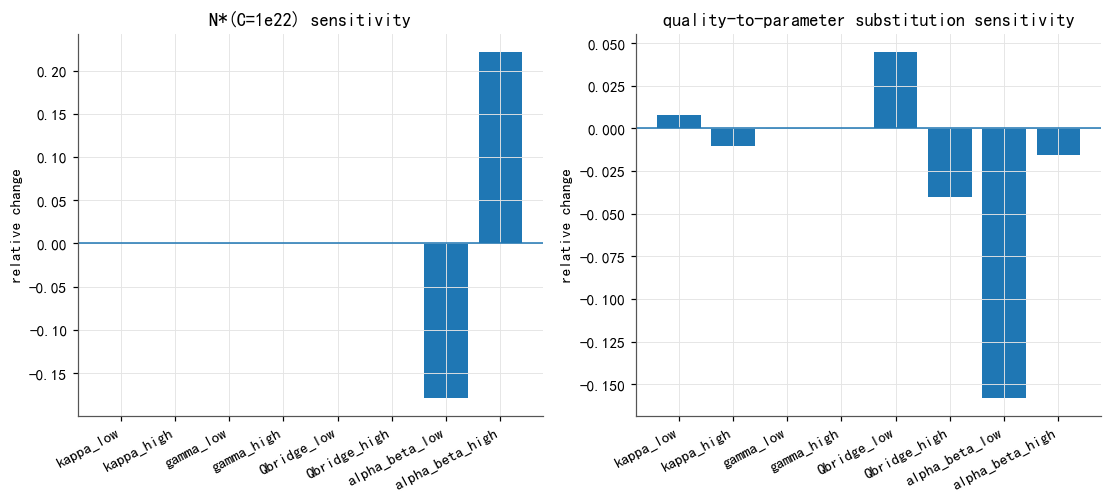

已写入 D:\华为杯研究生建模资料\第二十三届中国研究生数学建模竞赛 - 中文题目\中文题目\F题\output_q2\tables\q2_outputs_for_q3.json
SAED parameters: {'kappa': 0.45966131835818924, 'gamma_p_local': 0.06864347773751242, 'gamma_bootstrap': [0.0574, 0.0691, 0.079], 'c_Q_scenarios': (0.75, 1.0, 1.25)}


In [10]:
# ============ 7. 敏感性分析 + q2 -> q3 接口 ============
def nopt_with_params(C,Q_A,p,th,kappa,gamma,c_q=CQ_NOMINAL):
    C=float(C);p=np.asarray(p,float)
    lo=np.log(max(1e5,np.sqrt(C/6)/1e4));hi=np.log(min(1e15,np.sqrt(C/6)*1e4))
    obj=lambda z:float(L_general_with_params(np.exp(z),C/(6*np.exp(z)),Q_A,p,th,kappa,gamma,c_q))
    r=minimize(lambda z:obj(float(z[0])),[(lo+hi)/2],method='L-BFGS-B',bounds=[(lo,hi)])
    n=float(np.exp(r.x[0]));d=float(C/(6*n))
    return n,d,float(L_general_with_params(n,d,Q_A,p,th,kappa,gamma,c_q))

def n_equiv_mult_with_params(N,D,Q_A,dQ,p,th,kappa,gamma,c_q=CQ_NOMINAL):
    p=np.asarray(p,float);q2=min(float(Q_A)+float(dQ),1.0)
    target=float(L_general_with_params(N,D,Q_A,p,th,kappa,gamma,c_q))
    def f(x): return float(L_general_with_params(x,D,q2,p,th,kappa,gamma,c_q))-target
    lo=max(float(N)*1e-8,1e3);hi=max(float(N),1e4)
    while f(hi)>0 and hi<1e18: hi*=10
    if f(lo)*f(hi)>0: return np.nan
    return float(brentq(f,lo,hi,maxiter=300)/float(N))

alpha_ci=np.asarray(EXP_UNC['alpha_ci'],float);beta_ci=np.asarray(EXP_UNC['beta_ci'],float)
gamma_low,gamma_med,gamma_high=map(float,GAMMA_CI)
sens_cases=[
    ('point',TH,KAPPA,GAMMA_P,1.0),
    ('kappa_low',TH,float(KAPPA_CI[0]),GAMMA_P,1.0),
    ('kappa_high',TH,float(KAPPA_CI[1]),GAMMA_P,1.0),
    ('gamma_low',TH,KAPPA,gamma_low,1.0),
    ('gamma_high',TH,KAPPA,gamma_high,1.0),
    ('Qbridge_low',TH,KAPPA,GAMMA_P,0.75),
    ('Qbridge_high',TH,KAPPA,GAMMA_P,1.25),
    ('alpha_beta_low',recalib(float(alpha_ci[0]),float(beta_ci[0])),KAPPA,GAMMA_P,1.0),
    ('alpha_beta_high',recalib(float(alpha_ci[1]),float(beta_ci[1])),KAPPA,GAMMA_P,1.0)]
sens_rows=[]
for label,ths,ks,gs,cq in sens_cases:
    n,d,l=nopt_with_params(1e22,Q_BAR_A,P_RISK,ths,ks,gs,cq)
    nm=n_equiv_mult_with_params(1.04e9,3e11,Q_BAR_A,.1,P_RISK,ths,ks,gs,cq)
    sens_rows.append({'case':label,'alpha':ths['alpha'],'beta':ths['beta'],'kappa':ks,'gamma_p':gs,'c_Q':cq,
                      'Q_A':Q_BAR_A,'Q_B':float(bridge_QA_to_QB(Q_BAR_A,cq)),
                      'N_opt_C1e22':n,'D_opt_C1e22':d,'L_opt_C1e22':l,
                      'N_equiv_multiplier_QAplus0.1':nm})
SENS=pd.DataFrame(sens_rows);SENS.to_csv(TAB/'sensitivity.csv',index=False,encoding='utf-8-sig');display(SENS)

# 图 9：关键决策量的相对敏感性。Q-bridge 对固定 p 的 N_opt 理论上应近似不变，但会改变 Loss 与替代倍率。
base=SENS.iloc[0];fig,axs=plt.subplots(1,2,figsize=(12,4.5));x=np.arange(1,len(SENS));labs=SENS.case.iloc[1:]
axs[0].bar(x,SENS.N_opt_C1e22.iloc[1:].values/base.N_opt_C1e22-1);axs[0].axhline(0,lw=1)
axs[0].set_xticks(x);axs[0].set_xticklabels(labs,rotation=28,ha='right');axs[0].set_ylabel('relative change');axs[0].set_title('N*(C=1e22) sensitivity')
axs[1].bar(x,SENS['N_equiv_multiplier_QAplus0.1'].iloc[1:].values/base['N_equiv_multiplier_QAplus0.1']-1);axs[1].axhline(0,lw=1)
axs[1].set_xticks(x);axs[1].set_xticklabels(labs,rotation=28,ha='right');axs[1].set_ylabel('relative change');axs[1].set_title('quality-to-parameter substitution sensitivity')
savefig('fig09_sensitivity.png');plt.show()

interaction_records=INTERACTION_EVIDENCE.to_dict('records') if len(INTERACTION_EVIDENCE) else []
handoff={
 'model_name':'SAED-Modular-Separable',
 'formula':'L=E+(A*N^(-alpha)+B*D^(-beta))*psi_Q(T(Q_A;c_Q))*psi_p(p,N)',
 'identifiability_note':'Q and p are not jointly intervened in the attachments; multiplicative separability is the minimum identifiable bridge, not proof of no Q×p interaction.',
 'classic_law':{k:float(TH[k]) for k in ('E','A','alpha','B','beta')},
 'H1':{'claim':'cross-source transferability of the scale coordinate R(N,D), not universal identical exponents',
       'cross_family_bootstrap_grouping':'B4 by family; B5 by publication source',
       'exponent_uncertainty':EXP_UNC},
 'quality':{'kappa':float(KAPPA),'psi_Q_B':'1+kappa*(1-Q_B)',
            'selection':'B6-only AIC + B6 cluster-bootstrap gamma test',
            'outer_validation':'B7 novel Q_B={0.5,0.7} only',
            'B7_novelQ_RMSE':float(QUALITY_RMSE),'B7_novelQ_R2':float(QUALITY_R2),
            'Q_bridge':{'Q_A':'Q_res from Q1','Q_B':'B6/B7 Q_score','formula':'clip(1-c_Q*(1-Q_A),0,1)',
                        'nominal_c_Q':1.0,'sensitivity_c_Q':[0.75,1.25],
                        'Qbar_A_ref':float(Q_REF_A),'Qbar_A_risk':float(Q_BAR_A),
                        'Qbar_B_nominal_ref':float(Q_REF_B),'Qbar_B_nominal_risk':float(Q_BAR_B)}},
 'mixture_scale_transfer':{
    'N0':float(N0),'same_mixture_1M_60M_n':int(len(y1)),'same_mixture_Spearman':float(RANK_1M60),
    'b_1M':float(B1_MIX),'b_60M':float(B60_MIX),'s60':float(S60),
    'gamma_p_local':float(GAMMA_P),'gamma_p_matched_bootstrap_2p5_50_97p5':GAMMA_CI.tolist(),
    'psi_p':'1+(N/N0)^(-gamma_p)*(L_mix(p)/L_mix(p_ref)-1)',
    'scope_note':'gamma_p is directly identified only on matched 1M->60M recipes; use above 60M is extrapolation.'},
 'mixture_bridge':{'domain_order':DOM17,'intercept':float(C0),'epsilon':float(EPS_LOG),
   'a_i':dict(zip(DOM17,map(float,A_LOG))),'L_ref':float(L_REF),
   'p_ref':dict(zip(DOM17,map(float,P_REF))),'p_risk':dict(zip(DOM17,map(float,P_RISK))),
   'stable_SCI_interactions':SCI_SELECTED,'interaction_evidence':interaction_records},
 'axis_equivalent_resources':{'N_axis_equiv':'N*Phi^(-1/alpha)','D_axis_equiv':'D*Phi^(-1/beta)',
   'note':'separate one-axis loss-equivalent coordinates; not a unique same-compute configuration'},
 'domain_reallocation':{'formula':'Delta_(i<-k)=dL/dp_i-dL/dp_k under dp_i=+delta, dp_k=-delta',
   'file':'saed_pairwise_reallocation_effect_uniform.csv'},
 'quality_parameter_substitution':{'condition':'when gamma_p>=0: target_loss > limiting_loss and dL/dN<0 imply a unique finite root',
   'reverse_equivalence_note':'low-quality required-N multiplier is solved separately; it is not defined as reciprocal of the high-quality reduction factor'},
 'evidence_table':'saed_evidence_by_task.csv',
 'sensitivity_file':'sensitivity.csv',
 'cost_functions_appendixB':{'exp':{'gamma':1e7,'lambda':6.0},'power':{'gamma':5e9,'lambda':4.0},'log':{'gamma':2e9,'lambda':10.0}}
}
with open(TAB/'q2_outputs_for_q3.json','w',encoding='utf-8') as f:json.dump(handoff,f,ensure_ascii=False,indent=2)
summary={'model':'SAED-Modular-Separable',
 'core_innovation':'modular separable scaling + matched structure/amplitude transfer + quality-coordinate bridge + simplex reallocation + analytic substitution',
 'quality_outer_RMSE':float(QUALITY_RMSE),'quality_outer_R2':float(QUALITY_R2),
 'same_mixture_1M_60M_Spearman':float(RANK_1M60),'s60_matched':float(S60),'gamma_p_local':float(GAMMA_P),
 'gamma_p_bootstrap':GAMMA_CI.tolist(),'kappa':float(KAPPA),'Q_bridge_cq_scenarios':list(CQ_SCENARIOS),
 'data_split':'B1 fit; B2/B3,B4/B5 structural validation; B6 quality selection/fit; B7 novel-Q outer validation; B8 boundary sensitivity; A6-A9 matched recipes only for H2 transfer; B9/B10 extrapolation'}
with open(TAB/'saed_run_summary.json','w',encoding='utf-8') as f:json.dump(summary,f,ensure_ascii=False,indent=2)
print('已写入',TAB/'q2_outputs_for_q3.json')
print('SAED parameters:',{'kappa':KAPPA,'gamma_p_local':GAMMA_P,'gamma_bootstrap':np.round(GAMMA_CI,4).tolist(),'c_Q_scenarios':CQ_SCENARIOS})


## 8. 问题二小结与输出清单

**最终模型**。本问采用模块化可分离广义标度律
$$\boxed{
L(N,D,Q_A,\mathbf p)
=E+\left(AN^{-\alpha}+BD^{-\beta}\right)
\left[1+\kappa\left(1-T(Q_A;c_Q)\right)\right]
\left\{1+\left(\frac N{N_0}\right)^{-\gamma_p}[\psi_{p,0}(\mathbf p)-1]\right\}
},$$
其中
$$T(Q_A;c_Q)=\operatorname{clip}\{1-c_Q(1-Q_A),0,1\}.$$
$(E,A,\alpha,B,\beta)$ 由 B1 拟合；$\kappa$ 仅由 B6 识别并由 B7 新质量水平做外层验证；$\psi_{p,0}$ 来自问题一结构桥；$\gamma_p$ 改为只由 **1M↔60M matched recipes 的中心化响应幅度**识别，1B 不再因配比集合不同而参与主幅度参数拟合。$c_Q=1$ 是质量坐标中心桥接假设，并用 $0.75/1.25$ 做敏感性。

**H1：规模骨架迁移，而非指数普适**。B2/B3 检验 B1 标度坐标的族外与插值迁移；B4/B5 通过来源偏移、乘子和排序检验支持 $R(N,D)$ 的跨来源结构可迁移性。真实跨族指数允许漂移，第 6 节 B4 按 family、B5 按 publication source 做 cluster bootstrap，并把指数不确定性传播到外推，不再把 B1 的 $\alpha,\beta$ 写成所有来源严格共享的常数。

**H2：结构—幅度分离的配比迁移**。H2a 用 1M↔60M 的 256 个相同配比检验排序稳定性；H2b 对同一 recipes 的 $\psi_{p,0}$ 与中心化 Loss 分别估计 1M/60M 响应斜率，以 $s_{60}=b_{60}/b_{1M}$ 和成对 bootstrap 识别局部 $\gamma_p$。代码运行后应以 `h2_matched_amplitude_transfer.csv` 中的实际数值为准；该参数在 60M 以上只作为带不确定性的外推，不宣称已经被 1B/10B/70B 直接验证。

**H3：质量项与坐标桥**。质量形式选择与参数估计全部限定在 B6，B7 新 $Q_B=\{0.5,0.7\}$ 仅作外层验证；当前已知运行结果为 $\kappa\approx0.4597$、B7 外层 RMSE $\approx0.04671$、$R^2\approx0.9789$。B8 只作为不满足同一质量响应机制的边界敏感性证据。问题一 $Q_A=Q^{res}$ 与 B6/B7 的 $Q_B=Q_{score}$ 通过 $T(Q_A;c_Q)$ 显式连接，所有质量—资源数值结论同时报告 $c_Q$ 敏感性。

**指标口径**。不同任务使用不同且匹配目标的评价指标：绝对 Loss 预测用 RMSE/$R^2$；配比排序迁移用 Spearman/Pearson；配比幅度迁移用 matched response slope $s_{60}$ 及其 bootstrap 区间。它们分别回答不同问题，不再放在同一数轴上比较“综合提升”。

**轴向等效资源与替代关系**。$N_{\rm eq}^{(N)}=N\Phi^{-1/\alpha}$、$D_{\rm eq}^{(D)}=D\Phi^{-1/\beta}$ 被解释为分别沿参数轴和数据轴的 Loss 等效换算，不是同一固定算力下的唯一真实配置。质量—参数替代先检验解析存在条件和 $\partial L/\partial N<0$，再数值求根；“低质量需要放大多少参数”使用反向方程单独求解，不用高质量减参倍率的倒数代替。

**领域替代与互补**。由于 $\mathbf p$ 位于概率单纯形，不再使用无约束空间的 $-g_i/g_k$ 作为 MRS。最终输出
$$\Delta_{i\leftarrow k}=\partial L/\partial p_i-\partial L/\partial p_k$$
描述从域 $k$ 向域 $i$ 转移微小份额时的局部 Loss 变化；二阶交互表仅作为互补/协同或替代/拮抗的候选曲率证据。

**外推与物理约束**。B10 仍只作为估算 Loss 的内部一致性检查。跨族 bootstrap 回代 B1 时采用 $E,A,B\ge0$ 的正性约束重标定，避免非物理样本破坏单调性。联合外推带同时传播 $(\alpha,\beta)$、$\kappa$、matched $\gamma_p$ 与 $c_Q$ 的不确定性，统一称为**敏感性带**。

**Compute-Optimal 解释**。最终输出的是**配比尺度感知前沿**。固定 $\mathbf p$ 时，$\psi_Q$ 对 $N,D$ 只是正的常数乘子，因此改变 $Q_A$ 会降低/抬高最优 Loss，但不会单独改变 $N^\star:D^\star$；只有 $\psi_p(\mathbf p;N)$ 的尺度耦合会改变固定算力下的最优分配。

**输出文件**（`output_q2/`）：

* `figures/fig01–fig09*.png`：数据分布、经典前沿、H1 结构验证、质量识别、B7 外层验证、H2 matched 结构/幅度、轴向等效资源、外推敏感性与参数敏感性；
* `tables/classic_law_params.csv`、`classic_law_jackknife.csv`、`family_offsets_scales.csv`：经典标度律与 H1；
* `tables/quality_form_comparison.csv`、`saed_quality_parameters.json`、`saed_quality_final_validation.csv`：H3 形式选择、参数和外层验证；
* `tables/h2_structure_transfer_evidence.csv`、`h2_matched_amplitude_transfer.csv`、`h2_matched_gamma_bootstrap.csv`、`h2_nonmatched_scale_rank_check.csv`：H2 matched 结构/幅度与非匹配尺度辅助检查；
* `tables/saed_evidence_by_task.csv`：按任务分开的评价指标口径；
* `tables/saed_axis_equivalent_resources_and_elasticities.csv`、`saed_pairwise_reallocation_effect_uniform.csv`、`saed_domain_interaction_evidence.csv`、`saed_quality_parameter_substitution.csv`：轴向等效资源、单纯形领域再分配与质量—规模替代；
* `tables/exponent_uncertainty.json`、`saed_joint_extrapolation_sensitivity_band.csv`、`saed_mixture_scale_compute_optimal_frontier.csv`、`sensitivity.csv`：跨族/质量/配比尺度/质量坐标桥的外推与敏感性；
* `tables/q2_outputs_for_q3.json`：问题三统一接口；`saed_run_summary.json`：本问关键结果摘要。

**参考依据**：Hoffmann et al., *Training Compute-Optimal Large Language Models*, NeurIPS 2022；Xie et al., *DoReMi*, NeurIPS 2023；Muennighoff et al., *Scaling Data-Constrained Language Models*, NeurIPS 2023；Li et al., *DataComp-LM*, NeurIPS 2024；Liu et al., *RegMix: Data Mixture as Regression for Language Model Pre-training*, ICLR 2025。
